# 🛒 Müşteri Kaybı Tahmini, Müşteri Değeri ve Kampanya Optimizasyonu
### Uçtan uca bir e-ticaret müşteri zekâsı projesi

**Hazırlayan:** Mehmet Emre Ünlü

---

## İş Problemi

Bir online perakende şirketi, her ay müşterilerinin bir kısmını sessizce kaybediyor. Pazarlama ekibinin elinde sınırlı bir kampanya bütçesi var ve şu soruların cevabını istiyor:

1. **Kim gidecek?** Önümüzdeki 90 günde hangi müşteri alışveriş yapmayacak? *(churn sınıflandırması)*
2. **Giderse ne kaybederiz?** Bu müşterinin önümüzdeki 90 gündeki değeri ne kadar? *(gelir regresyonu)*
3. **Kime para harcamalıyız?** Bütçeyi hangi müşterilere ayırırsak **net kâr** en yüksek olur? *(kampanya optimizasyonu)*

Klasik RFM ve CLTV çalışmaları *"müşteri bugün nerede?"* sorusunu cevaplar. Bu proje bir adım ileri gidip **geleceği tahmin ediyor** ve tahmini **paraya çeviriyor**.

## Yol Haritası

| # | Bölüm | Teknik |
|---|---|---|
| 1 | Veri temizleme | İadeler, eksik ID'ler, aykırı değerler |
| 2 | Keşifçi analiz | Zaman serisi, ülke, alışveriş saatleri |
| 3 | Sızıntısız zaman bölmesi | Gözlem penceresi → tahmin penceresi |
| 4 | Özellik mühendisliği | RFM + 20'den fazla davranışsal özellik |
| 5 | RFM segmentleri | Segment bazlı gerçek churn oranları |
| 6 | Churn modeli | Kilitli test, eğitim setinde 5×5 CV ile seçim, zamana dayalı test, mevsim kalibrasyonu |
| 7 | Açıklanabilirlik | SHAP |
| 8 | Değer modeli | Hurdle yapı (churn × Tweedie), klasik BG-NBD × Gamma-Gamma ile kıyas ve karışım |
| 9 | Kampanya simülasyonu | Bağımsız değer vekili, eşit bütçe, bootstrap güven aralıkları |
| 10 | Canlı skorlama | Çok kanallı karar mantığı ile aksiyon listesi |
| 11 | A/B test tasarımı | Güç analizi ile örneklem büyüklüğü |

**Veri:** [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) (UCI) — İngiltere merkezli bir hediyelik eşya e-ticaret sitesinin 01.12.2010–09.12.2011 arası ~540 bin satırlık işlem kaydı.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, brier_score_loss,
                             mean_absolute_error, r2_score)
from sklearn.calibration import calibration_curve
import lightgbm as lgb
import shap

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)

# Tutarlı görsel stil
PALETTE = {"ana": "#2E5EAA", "vurgu": "#E4572E", "yesil": "#29A36A", "gri": "#8C8C8C", "sari": "#F3A712"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False})
print("Kütüphaneler hazır ✔")

Kütüphaneler hazır ✔


## 1. Veri Yükleme ve Temizleme

Veriyi yükleyip ilk bakışı atalım. Ham işlem verisinde dikkat edilmesi gereken üç tuzak var:
- **İadeler:** Fatura numarası `C` ile başlayan satırlar iptal/iade kayıtları.
- **Misafir alışverişleri:** `CustomerID` boş olan satırlar müşteriye bağlanamaz.
- **Teknik kalemler:** Posta ücreti, banka komisyonu, manuel düzeltme gibi ürün olmayan kodlar.

In [2]:
import os, urllib.request
VERI = "data/retail.csv"
if not os.path.exists(VERI):  # veri yoksa GitHub'daki kopyasından indir (~45 MB)
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/"
                               "master/data/retail-data/all/online-retail-dataset.csv", VERI)
df_raw = pd.read_csv(VERI, dtype={"CustomerID": "Int64", "InvoiceNo": str, "StockCode": str})
df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"], format="%m/%d/%Y %H:%M")
print(f"Satır: {len(df_raw):,}  |  Sütun: {df_raw.shape[1]}")
print(f"Tarih aralığı: {df_raw.InvoiceDate.min():%d.%m.%Y} → {df_raw.InvoiceDate.max():%d.%m.%Y}")
df_raw.head()

Satır: 541,909  |  Sütun: 8
Tarih aralığı: 01.12.2010 → 09.12.2011


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [3]:
ozet = pd.DataFrame({
    "eksik_oran_%": df_raw.isna().mean() * 100,
    "benzersiz": df_raw.nunique(),
    "tip": df_raw.dtypes.astype(str),
})
ozet

,eksik_oran_%,benzersiz,tip
InvoiceNo,0.00,25900,str
StockCode,0.00,4070,str
Description,0.27,4223,str
Quantity,0.00,722,int64
InvoiceDate,0.00,23260,datetime64[us]
UnitPrice,0.00,1630,float64
CustomerID,24.93,4372,Int64
Country,0.00,38,str


In [4]:
df = df_raw.copy()
adimlar = [("Ham veri", len(df))]

df = df[df["CustomerID"].notna()];                      adimlar.append(("CustomerID boş olanlar çıkarıldı", len(df)))
df["Iade"] = df["InvoiceNo"].str.startswith("C")
teknik = ["POST", "D", "M", "BANK CHARGES", "PADS", "DOT", "CRUK", "C2", "AMAZONFEE"]
df = df[~df["StockCode"].isin(teknik)];                 adimlar.append(("Teknik kalemler çıkarıldı", len(df)))
df = df[df["UnitPrice"] > 0];                           adimlar.append(("Fiyatı 0 olanlar çıkarıldı", len(df)))
df["Tutar"] = df["Quantity"] * df["UnitPrice"]

# İadeleri ayrı tut: hem özellik (iade oranı) olarak kullanacağız
iadeler = df[df["Iade"]].copy()
satislar = df[~df["Iade"] & (df["Quantity"] > 0)].copy()
adimlar.append(("Satışlar (iadeler hariç)", len(satislar)))

# Aykırı değerler: tek satırlık devasa siparişler (ör. 80.995 adetlik hatalı kayıt) tüm müşteri
# ortalamalarını bozar. %99.9 üstünü baskılıyoruz (silmek yerine: müşteri kaybolmasın).
for c in ["Quantity", "UnitPrice"]:
    ust = satislar[c].quantile(0.999)
    satislar[c] = satislar[c].clip(upper=ust)
satislar["Tutar"] = satislar["Quantity"] * satislar["UnitPrice"]
satislar["CustomerID"] = satislar["CustomerID"].astype(int)
iadeler["CustomerID"] = iadeler["CustomerID"].astype(int)

pd.DataFrame(adimlar, columns=["Adım", "Kalan satır"]).style.format({"Kalan satır": "{:,}"})

,Adım,Kalan satır
0,Ham veri,"541,909"
1,CustomerID boş olanlar çıkarıldı,"406,829"
2,Teknik kalemler çıkarıldı,"404,909"
3,Fiyatı 0 olanlar çıkarıldı,"404,876"
4,Satışlar (iadeler hariç),"396,337"


Temizlik sonrası elimizde müşteriye bağlanabilen, iadeler ayrıştırılmış ve aykırı değerleri baskılanmış satış verisi var. İadeleri çöpe atmadık: **iade oranı** churn için güçlü bir sinyal olabilir.

## 2. Keşifçi Veri Analizi

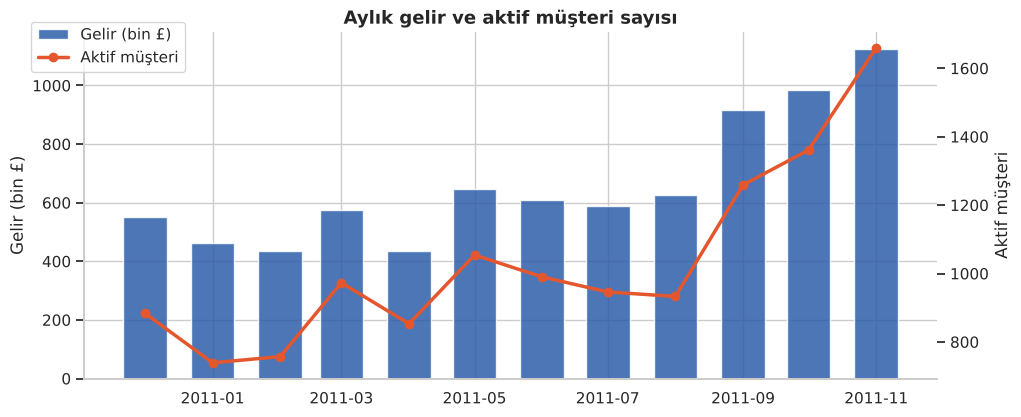

In [5]:
aylik = (satislar.set_index("InvoiceDate")
         .resample("MS").agg(Gelir=("Tutar", "sum"), Musteri=("CustomerID", "nunique")))
aylik = aylik.iloc[:-1]  # Aralık 2011 sadece 9 gün: yanıltmasın

fig, ax1 = plt.subplots()
ax1.bar(aylik.index, aylik["Gelir"] / 1e3, width=20, color=PALETTE["ana"], alpha=.85, label="Gelir (bin £)")
ax1.set_ylabel("Gelir (bin £)")
ax2 = ax1.twinx()
ax2.plot(aylik.index, aylik["Musteri"], color=PALETTE["vurgu"], marker="o", lw=2.5, label="Aktif müşteri")
ax2.set_ylabel("Aktif müşteri"); ax2.grid(False)
ax1.set_title("Aylık gelir ve aktif müşteri sayısı")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.92)); plt.show()

**Gözlem:** Güçlü bir **mevsimsellik** var: Eylül–Kasım arası gelir neredeyse ikiye katlanıyor (yılbaşı hediyelik alışverişi). Bu, modeli kurarken önemli: tahmin penceremizi rastgele seçersek mevsim etkisini churn sanabiliriz. Bu yüzden 3. bölümde **zaman tabanlı** bir bölme kullanacağız.

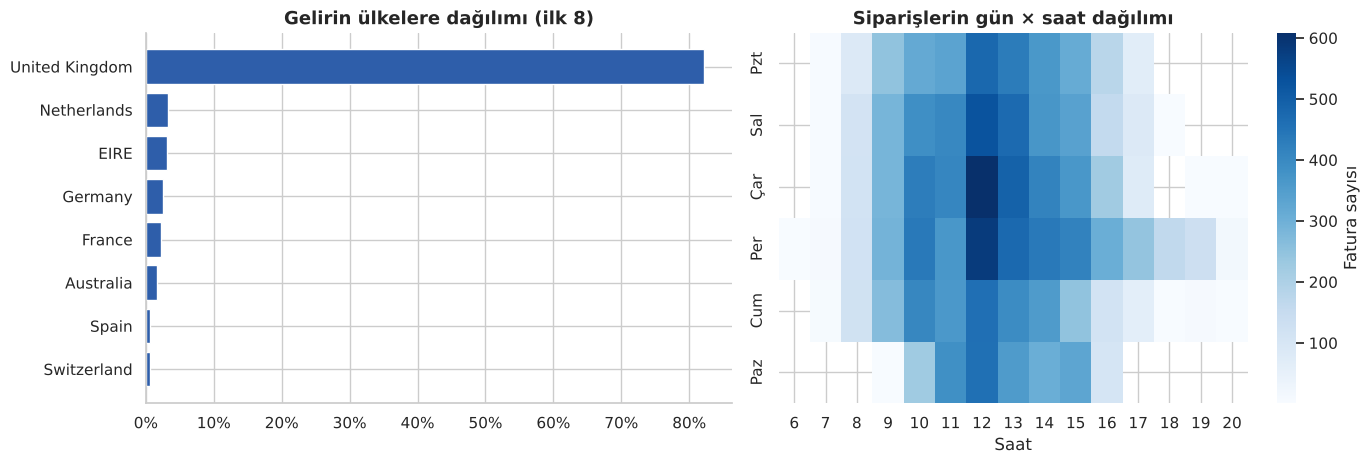

İngiltere'nin gelir payı: %82.2


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ulke = satislar.groupby("Country")["Tutar"].sum().sort_values(ascending=False)
ulke_pay = (ulke / ulke.sum()).head(8)
axes[0].barh(ulke_pay.index[::-1], ulke_pay.values[::-1] * 100, color=PALETTE["ana"])
axes[0].set_title("Gelirin ülkelere dağılımı (ilk 8)"); axes[0].xaxis.set_major_formatter(mtick.PercentFormatter())

satislar["Gun"] = satislar["InvoiceDate"].dt.dayofweek
satislar["Saat"] = satislar["InvoiceDate"].dt.hour
isi = (satislar.drop_duplicates("InvoiceNo").pivot_table(index="Gun", columns="Saat", values="InvoiceNo", aggfunc="count"))
isi.index = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"][:len(isi)] if len(isi) == 7 else [["Pzt","Sal","Çar","Per","Cum","Cmt","Paz"][i] for i in isi.index]
sns.heatmap(isi, cmap="Blues", ax=axes[1], cbar_kws={"label": "Fatura sayısı"})
axes[1].set_title("Siparişlerin gün × saat dağılımı"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()
print(f"İngiltere'nin gelir payı: %{ulke.iloc[0] / ulke.sum() * 100:.1f}")

**Gözlem:** Gelirin büyük kısmı İngiltere'den geliyor ve siparişler hafta içi mesai saatlerinde yoğunlaşıyor; **cumartesi neredeyse hiç sipariş yok**. Bu, müşteri kitlesinin önemli bir kısmının bireysel değil **toptancı/kurumsal** olduğunu düşündürüyor. Kampanya zamanlamasında (ör. e-postayı salı sabahı göndermek) işe yarar bir içgörü.

## 3. Sızıntısız Zaman Bölmesi: Problemi Doğru Kurmak

Churn tahmininde en sık yapılan hata **veri sızıntısıdır**: geleceği bilen özelliklerle model kurup harika ama sahte skorlar almak. Bunu önlemek için veriyi zaman ekseninde ikiye bölüyoruz:

```
|←────────── Gözlem penceresi (özellikler) ──────────→|←── Tahmin penceresi (hedef) ──→|
01.12.2010                                      KESİM = 11.09.2011               09.12.2011
```

- **Özellikler** sadece kesim tarihinden *önceki* davranıştan hesaplanır.
- **Hedef (churn):** Kesim tarihinden sonraki 90 günde **hiç alışveriş yapmayan** müşteri = 1.
- **Hedef (değer):** Aynı 90 günde müşterinin bıraktığı gelir.

Böylece model, gerçek hayatta olacağı gibi, sadece geçmişi görerek geleceği tahmin ediyor.

In [7]:
TAHMIN_GUN = 90
SON_TARIH = satislar["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
KESIM = SON_TARIH - pd.Timedelta(days=TAHMIN_GUN)
print(f"Kesim tarihi: {KESIM:%d.%m.%Y}  |  Tahmin penceresi sonu: {SON_TARIH:%d.%m.%Y}")

Kesim tarihi: 11.09.2011  |  Tahmin penceresi sonu: 10.12.2011


## 4. Özellik Mühendisliği

Klasik RFM'nin üç metriği güçlü ama yetersiz. Bir müşterinin *gitmek üzere* olduğunu anlatan asıl sinyaller **davranıştaki değişimdir**. Aşağıdaki fonksiyon herhangi bir kesim tarihi için müşteri başına şu özellik gruplarını üretiyor:

| Grup | Özellikler | Neyi yakalar? |
|---|---|---|
| **RFM** | recency, frequency, monetary | Klasik müşteri durumu |
| **Yaşam süresi** | tenure, ilk alışverişten bu yana gün | Sadakat derinliği |
| **Ritim** | siparişler arası ortalama/std gün, *gecikme oranı* | Müşteri "her zamanki" zamanında mı? |
| **Trend** | son 30/90 gün harcama, 90 günlük trend oranı | Harcama düşüyor mu? |
| **Sepet** | ortalama sepet, ürün çeşitliliği, ortalama birim fiyat | Ne tür müşteri? |
| **Memnuniyetsizlik** | iade oranı | Sorun yaşıyor mu? |
| **Bağlam** | İngiltere mi, aktif ay sayısı | Coğrafya ve süreklilik |

En değerli özelliklerden biri **gecikme oranı**: `recency / ortalama sipariş aralığı`. Ayda bir alışveriş yapan biri için 40 gün sessizlik alarm, üç ayda bir alan biri için normaldir.

In [8]:
def ozellik_uret(satis, iade, kesim):
    s = satis[satis["InvoiceDate"] < kesim]
    r = iade[iade["InvoiceDate"] < kesim]

    fatura = (s.groupby(["CustomerID", "InvoiceNo"])
                .agg(tarih=("InvoiceDate", "min"), tutar=("Tutar", "sum"),
                     kalem=("StockCode", "nunique")).reset_index())

    g = fatura.groupby("CustomerID")
    X = pd.DataFrame({
        "recency": (kesim - g["tarih"].max()).dt.days,
        "tenure": (kesim - g["tarih"].min()).dt.days,
        "frequency": g["InvoiceNo"].nunique(),
        "monetary": g["tutar"].sum(),
        "ort_sepet": g["tutar"].mean(),
        "max_sepet": g["tutar"].max(),
        "ort_kalem": g["kalem"].mean(),
    })

    # Ritim: siparişler arası süre
    fatura = fatura.sort_values(["CustomerID", "tarih"])
    fatura["aralik"] = fatura.groupby("CustomerID")["tarih"].diff().dt.days
    rit = fatura.groupby("CustomerID")["aralik"].agg(["mean", "std"])
    X["ort_aralik"] = rit["mean"]
    X["std_aralik"] = rit["std"]
    X["gecikme_orani"] = X["recency"] / X["ort_aralik"].clip(lower=1)  # aynı gün tekrar sipariş → 0'a bölme olmasın

    # Trend: son 30 / 90 / önceki 90 gün
    for gun in (30, 90):
        son = fatura[fatura["tarih"] >= kesim - pd.Timedelta(days=gun)]
        X[f"harcama_son{gun}"] = son.groupby("CustomerID")["tutar"].sum()
        X[f"siparis_son{gun}"] = son.groupby("CustomerID")["InvoiceNo"].nunique()
    onceki = fatura[(fatura["tarih"] >= kesim - pd.Timedelta(days=180)) &
                    (fatura["tarih"] < kesim - pd.Timedelta(days=90))]
    X["harcama_onceki90"] = onceki.groupby("CustomerID")["tutar"].sum()
    X[["harcama_son30", "harcama_son90", "siparis_son30", "siparis_son90", "harcama_onceki90"]] = \
        X[["harcama_son30", "harcama_son90", "siparis_son30", "siparis_son90", "harcama_onceki90"]].fillna(0)
    X["trend_90"] = (X["harcama_son90"] + 1) / (X["harcama_onceki90"] + 1)

    # Sepet profili
    X["urun_cesitliligi"] = s.groupby("CustomerID")["StockCode"].nunique()
    X["ort_birim_fiyat"] = s.groupby("CustomerID")["UnitPrice"].mean()
    X["aktif_ay"] = s.groupby("CustomerID")["InvoiceDate"].apply(lambda d: d.dt.to_period("M").nunique())
    X["aylik_harcama"] = X["monetary"] / X["aktif_ay"]

    # Memnuniyetsizlik: iade oranı
    iade_tutar = (-r.groupby("CustomerID")["Tutar"].sum()).reindex(X.index).fillna(0)
    X["iade_orani"] = (iade_tutar / X["monetary"]).clip(0, 1)

    # Bağlam
    ulke = s.groupby("CustomerID")["Country"].agg(lambda c: c.mode().iloc[0])
    X["ingiltere"] = (ulke == "United Kingdom").astype(int)
    return X


def hedef_uret(satis, X, kesim, gun=TAHMIN_GUN):
    p = satis[(satis["InvoiceDate"] >= kesim) & (satis["InvoiceDate"] < kesim + pd.Timedelta(days=gun))]
    gelecek = p.groupby("CustomerID")["Tutar"].sum().reindex(X.index).fillna(0)
    return (gelecek == 0).astype(int).rename("churn"), gelecek.rename("gelecek_gelir")


X = ozellik_uret(satislar, iadeler, KESIM)
y_churn, y_gelir = hedef_uret(satislar, X, KESIM)
print(f"Müşteri sayısı: {len(X):,}  |  Özellik sayısı: {X.shape[1]}")
print(f"Churn oranı (90 gün): %{y_churn.mean() * 100:.1f}")
print(f"Kalan müşterilerin 90 günlük toplam geliri: £{y_gelir.sum():,.0f}")
X.describe().T[["mean", "50%", "min", "max"]]

Müşteri sayısı: 3,368  |  Özellik sayısı: 22
Churn oranı (90 gün): %43.0
Kalan müşterilerin 90 günlük toplam geliri: £2,573,781


,mean,50%,min,max
recency,95.22,74.00,1.00,283.00
tenure,182.84,193.00,1.00,283.00
frequency,3.51,2.00,1.00,131.00
monetary,"1,525.77",549.16,2.90,"175,934.18"
ort_sepet,361.27,277.64,2.90,"9,278.86"
max_sepet,522.99,335.30,2.90,"22,736.33"
ort_kalem,20.35,16.00,1.00,262.00
ort_aralik,59.04,46.00,0.00,270.00
std_aralik,31.90,25.08,0.00,188.80
gecikme_orani,6.01,0.84,0.01,283.00


Müşterilerin yaklaşık %43'ü önümüzdeki 90 günde geri gelmiyor. Sınıflar görece dengeli olduğu için yapay örnekleme (SMOTE vb.) gerekmiyor.

Özellikler hedefle nasıl ilişkili? Önce en sezgisel iki sinyale bakalım:

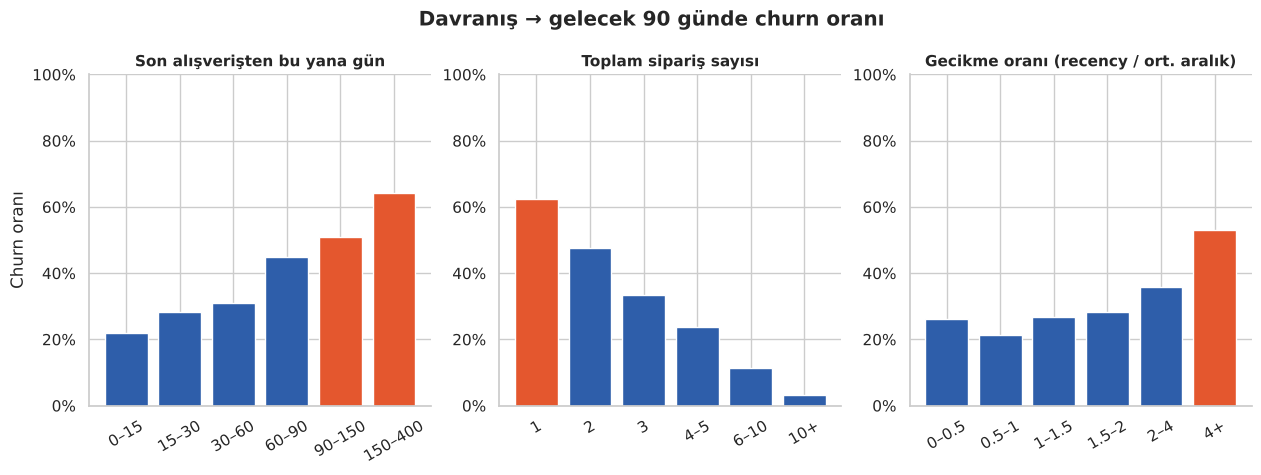

Not: gecikme oranı sadece 2+ siparişi olan müşteriler için tanımlı (tek siparişliler NaN).


In [9]:
df_eda = X.assign(churn=y_churn)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

for ax, col, baslik, bins in [
    (axes[0], "recency", "Son alışverişten bu yana gün", [0, 15, 30, 60, 90, 150, 400]),
    (axes[1], "frequency", "Toplam sipariş sayısı", [0, 1, 2, 3, 5, 10, 300]),
    (axes[2], "gecikme_orani", "Gecikme oranı (recency / ort. aralık)", [0, .5, 1, 1.5, 2, 4, 1000]),
]:
    grup = df_eda.groupby(pd.cut(df_eda[col], bins, include_lowest=True), observed=True)["churn"].mean() * 100
    etiket = [f"{int(i.left)}–{int(i.right)}" if col != "gecikme_orani" else f"{i.left:g}–{i.right:g}" for i in grup.index]
    if col == "gecikme_orani": etiket[0] = "0–0.5"; etiket[-1] = "4+"
    if col == "frequency": etiket = ["1", "2", "3", "4–5", "6–10", "10+"]
    renk = [PALETTE["vurgu"] if v > 50 else PALETTE["ana"] for v in grup.values]
    ax.bar(etiket, grup.values, color=renk)
    ax.set_title(baslik, fontsize=11); ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Churn oranı")
plt.suptitle("Davranış → gelecek 90 günde churn oranı", fontweight="bold", y=1.03); plt.show()
print("Not: gecikme oranı sadece 2+ siparişi olan müşteriler için tanımlı (tek siparişliler NaN).")

**Gözlem:** Üç sinyal de beklendiği gibi güçlü. Özellikle tek siparişli müşteriler çok yüksek oranda geri dönmüyor: **ikinci siparişi kazanmak**, en kritik kampanya hedeflerinden biri. Gecikme oranı 1'in üzerine çıktığında (müşteri "her zamanki" süresini aştığında) churn riski hızla tırmanıyor.

## 5. RFM Segmentleri: Klasik Yaklaşım Ne Söylüyor?

Kendi önceki RFM projemdeki segmentasyonu burada tekrar kuruyorum. Ama bu sefer bir farkla: segmentlerin **gerçekte** ne kadar churn ettiğini ölçebiliyoruz, çünkü geleceği biliyoruz.

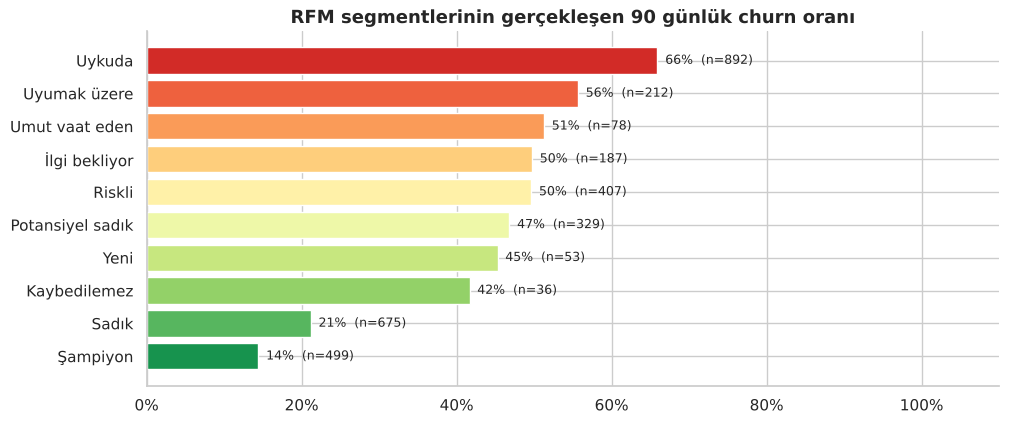

,Musteri,Churn_orani,Ort_harcama,Gelecek_gelir
Segment,,,,
Şampiyon,499,14.4%,"£5,274","£1,325,317"
Sadık,675,21.2%,"£2,033","£643,644"
Kaybedilemez,36,41.7%,"£1,936","£27,352"
Yeni,53,45.3%,£341,"£17,033"
Potansiyel sadık,329,46.8%,£604,"£114,726"
Riskli,407,49.6%,£810,"£137,112"
İlgi bekliyor,187,49.7%,£635,"£54,264"
Umut vaat eden,78,51.3%,£491,"£19,250"
Uyumak üzere,212,55.7%,£346,"£64,255"


In [10]:
rfm = X[["recency", "frequency", "monetary"]].copy()
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RF"] = rfm["R"].astype(str) + rfm["F"].astype(str)

seg_map = {
    r"[1-2][1-2]": "Uykuda", r"[1-2][3-4]": "Riskli", r"[1-2]5": "Kaybedilemez",
    r"3[1-2]": "Uyumak üzere", r"33": "İlgi bekliyor", r"[3-4][4-5]": "Sadık",
    r"41": "Umut vaat eden", r"51": "Yeni", r"[4-5][2-3]": "Potansiyel sadık", r"5[4-5]": "Şampiyon",
}
rfm["Segment"] = rfm["RF"].replace(seg_map, regex=True)

seg = (rfm.assign(churn=y_churn, gelecek=y_gelir)
          .groupby("Segment")
          .agg(Musteri=("churn", "size"), Churn_orani=("churn", "mean"),
               Ort_harcama=("monetary", "mean"), Gelecek_gelir=("gelecek", "sum"))
          .sort_values("Churn_orani"))

fig, ax = plt.subplots(figsize=(11, 4.6))
renk = sns.color_palette("RdYlGn_r", len(seg))
bar = ax.barh(seg.index, seg["Churn_orani"] * 100, color=renk)
for b, n in zip(bar, seg["Musteri"]):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f"{b.get_width():.0f}%  (n={n})", va="center", fontsize=9)
ax.set_xlim(0, 110); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("RFM segmentlerinin gerçekleşen 90 günlük churn oranı"); plt.show()
seg.style.format({"Churn_orani": "{:.1%}", "Ort_harcama": "£{:,.0f}", "Gelecek_gelir": "£{:,.0f}", "Musteri": "{:,}"})

**Gözlem:** RFM segmentleri sıralamayı doğru yapıyor: Şampiyonlar en az, Uykudakiler en çok churn ediyor. **Ama segmentlerin içi homojen değil.** Örneğin "Riskli" segmentteki her müşteriye aynı kampanyayı göndermek, zaten geri gelecek olanlara boşa para harcamak demek. Bize müşteri bazında, **olasılık** düzeyinde bir tahmin lazım. Bu da makine öğreniminin işi.

## 6. Churn Modeli

Müşterileri %75 eğitim / %25 test olarak ayırıyoruz (sınıf oranını koruyarak). İki model kıyaslıyoruz:
- **Lojistik regresyon:** Basit, yorumlanabilir bir referans çizgisi.
- **LightGBM:** Doğrusal olmayan ilişkileri ve etkileşimleri yakalayan gradient boosting.

> ⚠️ Kesim tarihini koruduğumuz için, buradaki rastgele müşteri bölmesi sızıntı yaratmaz: tüm özellikler aynı kesimden önce, tüm hedefler sonra hesaplanıyor.

> 🔒 **Kilitli test seti:** Test müşterileri bu noktada ayrılıyor ve **hiçbir model kararında kullanılmıyor**. Hiperparametre seçimi, model kıyasları ve değer modeli seçimi yalnızca eğitim müşterileri üzerinde yapılıyor; test seti en sonda **bir kez** açılıyor. (Zamana dayalı doğrulama için bkz. 6.3.)

In [11]:
OZELLIKLER = list(X.columns)
X_tr, X_te, yc_tr, yc_te, yg_tr, yg_te = train_test_split(
    X, y_churn, y_gelir, test_size=0.25, stratify=y_churn, random_state=RANDOM_STATE)
print(f"Eğitim: {len(X_tr):,} müşteri  |  Kilitli test: {len(X_te):,} müşteri")

# Lojistik regresyon: eksik değerleri doldur, çarpık dağılımları log'la, ölçekle
def lr_hazirla(d):
    d = d.copy()
    d[["ort_aralik", "std_aralik"]] = d[["ort_aralik", "std_aralik"]].fillna(d["tenure"].max())
    d["gecikme_orani"] = d["gecikme_orani"].fillna(d["gecikme_orani"].max())
    carpik = ["recency", "frequency", "monetary", "ort_sepet", "max_sepet", "harcama_son30", "harcama_son90",
              "harcama_onceki90", "urun_cesitliligi", "aylik_harcama", "trend_90", "gecikme_orani", "ort_birim_fiyat"]
    d[carpik] = np.log1p(d[carpik].clip(lower=0))
    return d

# İlk denemedeki LightGBM ayarları (karşılaştırma için saklıyoruz)
lgb_ilk = dict(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=40,
               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
               random_state=RANDOM_STATE, verbose=-1)

Eğitim: 2,526 müşteri  |  Kilitli test: 842 müşteri


### 6.1 Model seçimi: Tek bir skora güvenebilir miyiz?

~840 müşterilik bir test setinde AUC kendi başına **±0.02 civarında** oynar: bir iyileştirmeyi "test skoru arttı" diye kabul etmek, şansı başarı sanmak olabilir. Bu yüzden model kararlarını **yalnızca eğitim müşterileri üzerinde 5×5 tekrarlı çapraz doğrulama** ile veriyoruz: 25 farklı bölme, her model aynı bölmelerde.

Geliştirme sırasında denediğim fikirler:

| Deney | Fikir | Sonuç |
|---|---|---|
| **Hiperparametre ayarı** | Sığ ağaç, düşük öğrenme hızı | ✅ Belirgin ve tutarlı artış (aşağıda yeniden yapılıyor) |
| Yeni özellikler (8 adet) | Yılbaşı ürün payı, son 3 sipariş ritmi, sipariş trendi vb. | ➖ Fark yok |
| Monoton kısıtlar | Recency ↑ risk, frequency ↓ risk zorunlu | ➖ Fark yok |
| Ensemble (LightGBM + LR) | İki modelin ortalaması | ➖ Ayarlı LightGBM'den biraz kötü |
| Çoklu kesim tarihi | 9 farklı kesimle eğitim verisini 8 katına çıkar | ➖ Farklı mevsimlerin hedefi karışıyor |
| BG-NBD / Gamma-Gamma özellikleri | Klasik CLTV modelinin beklenen işlem sayısı ve sepet tahmini | ➖ Fark yok; bilgisi mevcut özelliklerde zaten var |
| Ürün zevk profili | Alınan ürünlerden TF-IDF + SVD ile 12 boyutlu "ne alıyor" vektörü | ➖ Fark yok |

Aşağıdaki kod final seçimi **şeffaf ve tekrar üretilebilir** şekilde, sadece eğitim setinde yapıyor: önce 24 kombinasyonluk bir ızgara taraması, sonra kazanan ayarın 5×5 tekrarlı CV ile ilk modele ve lojistik regresyona karşı kıyası.

Kazanan ayar: {'num_leaves': 4, 'learning_rate': 0.01, 'n_estimators': 400, 'colsample_bytree': 0.5} | CV AUC: 0.759
En iyi 3 ayarın skorları: [0.7591 0.759  0.7571]


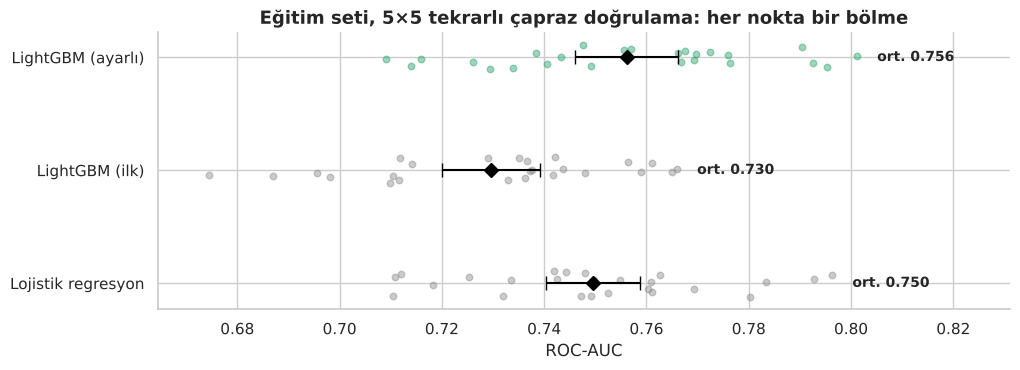

Ayarlı - ilk LightGBM: +0.0265 AUC  |  25 bölmenin 25'inde daha iyi


In [12]:
import itertools
izgara = [dict(lgb_ilk, num_leaves=nl, learning_rate=lr_, n_estimators=n, colsample_bytree=cs)
          for nl, lr_, n, cs in itertools.product([4, 7, 15], [0.01, 0.02], [400, 800], [0.5, 0.8])]
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
izgara_skor = [cross_val_score(lgb.LGBMClassifier(**p), X_tr, yc_tr, cv=cv5, scoring="roc_auc").mean() for p in izgara]
lgb_params = izgara[int(np.argmax(izgara_skor))]
print("Kazanan ayar:", {k: lgb_params[k] for k in ["num_leaves", "learning_rate", "n_estimators", "colsample_bytree"]},
      f"| CV AUC: {max(izgara_skor):.3f}")
print("En iyi 3 ayarın skorları:", np.round(sorted(izgara_skor)[-3:][::-1], 4))

bolmeler = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7).split(X_tr, yc_tr))
def tekrarli_cv(tahmin_fn):
    return np.array([roc_auc_score(yc_tr.iloc[b], tahmin_fn(X_tr.iloc[a], yc_tr.iloc[a], X_tr.iloc[b])) for a, b in bolmeler])

lr_fn = lambda xa, ya, xb: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)).fit(lr_hazirla(xa), ya).predict_proba(lr_hazirla(xb))[:, 1]
lgb_fn = lambda p: (lambda xa, ya, xb: lgb.LGBMClassifier(**p).fit(xa, ya).predict_proba(xb)[:, 1])

skor = {"Lojistik regresyon": tekrarli_cv(lr_fn),
        "LightGBM (ilk)": tekrarli_cv(lgb_fn(lgb_ilk)),
        "LightGBM (ayarlı)": tekrarli_cv(lgb_fn(lgb_params))}

fig, ax = plt.subplots(figsize=(11, 3.6))
for i, (ad, a) in enumerate(skor.items()):
    renk = PALETTE["yesil"] if "ayarlı" in ad else PALETTE["gri"]
    ax.scatter(a, np.full(len(a), i) + np.random.default_rng(i).uniform(-.12, .12, len(a)), color=renk, alpha=.45, s=22)
    ax.errorbar(a.mean(), i, xerr=1.96 * a.std() / np.sqrt(len(a)), fmt="D", color="black", ms=7, capsize=5)
    ax.text(a.max() + .004, i, f"ort. {a.mean():.3f}", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(range(len(skor))); ax.set_yticklabels(skor.keys())
ax.set(title="Eğitim seti, 5×5 tekrarlı çapraz doğrulama: her nokta bir bölme", xlabel="ROC-AUC")
ax.set_xlim(min(a.min() for a in skor.values()) - .01, max(a.max() for a in skor.values()) + .03); plt.show()

fark = skor["LightGBM (ayarlı)"] - skor["LightGBM (ilk)"]
print(f"Ayarlı - ilk LightGBM: {fark.mean():+.4f} AUC  |  25 bölmenin {(fark > 0).sum()}'inde daha iyi")

**Ders:** İlk LightGBM modeli **ezberliyordu** (fazla derin ağaçlar, ~2.500 eğitim satırı için fazla karmaşık). Daha sade ve düzenlileştirilmiş bir model hem daha yüksek AUC hem daha iyi kalibrasyon veriyor. Ekstra karmaşıklık (yeni özellik, ensemble) fayda getirmediği için **en sade kazanan modeli** seçiyoruz.

### 6.2 Kilitli test setinde tek seferlik değerlendirme

Tüm kararlar verildi. Şimdi modelleri tüm eğitim setiyle eğitip test setini **ilk ve tek kez** açıyoruz.

In [13]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5)).fit(lr_hazirla(X_tr), yc_tr)
p_lr = lr.predict_proba(lr_hazirla(X_te))[:, 1]
p_ilk = lgb.LGBMClassifier(**lgb_ilk).fit(X_tr, yc_tr).predict_proba(X_te)[:, 1]
clf = lgb.LGBMClassifier(**lgb_params).fit(X_tr, yc_tr)
p_lgb = clf.predict_proba(X_te)[:, 1]

sonuc = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(yc_te, p) for p in (p_lr, p_ilk, p_lgb)],
    "PR-AUC": [average_precision_score(yc_te, p) for p in (p_lr, p_ilk, p_lgb)],
    "Brier (↓)": [brier_score_loss(yc_te, p) for p in (p_lr, p_ilk, p_lgb)],
}, index=["Lojistik regresyon", "LightGBM (ilk)", "LightGBM (ayarlı, final)"])
sonuc.style.format("{:.3f}").highlight_max(subset=["ROC-AUC", "PR-AUC"], color="#d4edda").highlight_min(subset=["Brier (↓)"], color="#d4edda")

,ROC-AUC,PR-AUC,Brier (↓)
Lojistik regresyon,0.731,0.638,0.207
LightGBM (ilk),0.740,0.640,0.207
"LightGBM (ayarlı, final)",0.739,0.652,0.203


Tek bir AUC sayısı iş birimine pek bir şey anlatmaz. Asıl soru: **"En riskli %20'yi hedeflersek, gidecek müşterilerin ne kadarını yakalarız?"**

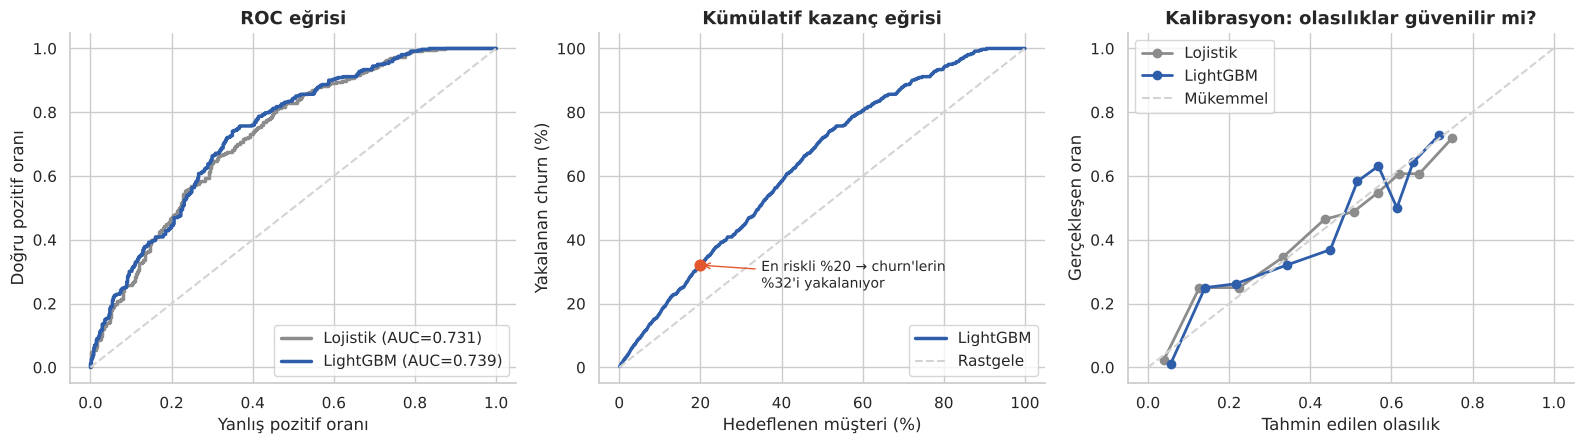

Risk dilimlerine göre gerçek churn oranı (1 = en riskli %10):
dilim
10     1.2%
9     25.0%
8     26.2%
7     32.1%
6     36.9%
5     58.3%
4     63.1%
3     50.0%
2     64.3%
1     72.9%


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# ROC
for p, ad, renk in [(p_lr, "Lojistik", PALETTE["gri"]), (p_lgb, "LightGBM", PALETTE["ana"])]:
    fpr, tpr, _ = roc_curve(yc_te, p)
    axes[0].plot(fpr, tpr, lw=2.5, color=renk, label=f"{ad} (AUC={roc_auc_score(yc_te, p):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="lightgray")
axes[0].set(title="ROC eğrisi", xlabel="Yanlış pozitif oranı", ylabel="Doğru pozitif oranı"); axes[0].legend()

# Kümülatif kazanç (gain)
sira = np.argsort(-p_lgb)
yakalanan = np.cumsum(yc_te.values[sira]) / yc_te.sum()
oran = np.arange(1, len(sira) + 1) / len(sira)
axes[1].plot(oran * 100, yakalanan * 100, lw=2.5, color=PALETTE["ana"], label="LightGBM")
axes[1].plot([0, 100], [0, 100], "--", color="lightgray", label="Rastgele")
k = int(0.2 * len(sira))
axes[1].scatter([20], [yakalanan[k] * 100], color=PALETTE["vurgu"], zorder=5, s=60)
axes[1].annotate(f"En riskli %20 → churn'lerin\n%{yakalanan[k]*100:.0f}'i yakalanıyor", (20, yakalanan[k] * 100),
                 xytext=(35, 25), arrowprops=dict(arrowstyle="->", color=PALETTE["vurgu"]), fontsize=10)
axes[1].set(title="Kümülatif kazanç eğrisi", xlabel="Hedeflenen müşteri (%)", ylabel="Yakalanan churn (%)"); axes[1].legend(loc="lower right")

# Kalibrasyon
for p, ad, renk in [(p_lr, "Lojistik", PALETTE["gri"]), (p_lgb, "LightGBM", PALETTE["ana"])]:
    gercek, tahmin = calibration_curve(yc_te, p, n_bins=10, strategy="quantile")
    axes[2].plot(tahmin, gercek, marker="o", lw=2, color=renk, label=ad)
axes[2].plot([0, 1], [0, 1], "--", color="lightgray", label="Mükemmel")
axes[2].set(title="Kalibrasyon: olasılıklar güvenilir mi?", xlabel="Tahmin edilen olasılık", ylabel="Gerçekleşen oran"); axes[2].legend()
plt.tight_layout(); plt.show()

dilim = pd.qcut(pd.Series(p_lgb).rank(method="first"), 10, labels=range(10, 0, -1))
lift = pd.DataFrame({"dilim": dilim.values, "churn": yc_te.values}).groupby("dilim", observed=True)["churn"].mean().sort_index()
print("Risk dilimlerine göre gerçek churn oranı (1 = en riskli %10):")
print((lift * 100).round(1).astype(str).add("%").to_string())

**Gözlem:**
- **Kazanç eğrisi:** En riskli %20'lik dilim, gidecek müşterilerin üçte birini yakalıyor (rastgele seçimde bu oran %20). Risk dilimleri tablosunda fark daha net: en riskli %10'un dörtte üçü gerçekten gidiyor, en güvenli %10'da ise bu oran %5'in altında.
- **Kalibrasyon:** LightGBM'in olasılıkları köşegene yakın. Yani model "%70 risk" dediğinde gerçekten yaklaşık %70'i gidiyor. **Bu, 9. bölümdeki para hesabı için kritik:** olasılıkları doğrudan beklenen kayıp hesabında kullanacağız.

### 6.3 Zamana dayalı geriye dönük test: Model gelecekte de çalışır mı?

Şimdiye kadarki tüm testler **aynı kesim tarihinde, farklı müşteriler** üzerindeydi. Gerçek hayatta ise model bugün eğitilip **gelecekteki** bir dönemde kullanılır. Bunu taklit etmek için üç geriye dönük test kuruyoruz: model bir kesimde eğitiliyor, hedef penceresi tamamen bittikten sonraki (90 gün sonraki) kesimde test ediliyor. Böylece eğitim ve test arasında hiçbir zaman örtüşmesi olmuyor.

```
Eğitim kesimi ──(90 gün hedef)──▶ Test kesimi ──(90 gün hedef)──▶
```

Son test (Haziran → Eylül), modelin üretimde nasıl çalışacağının birebir provası.

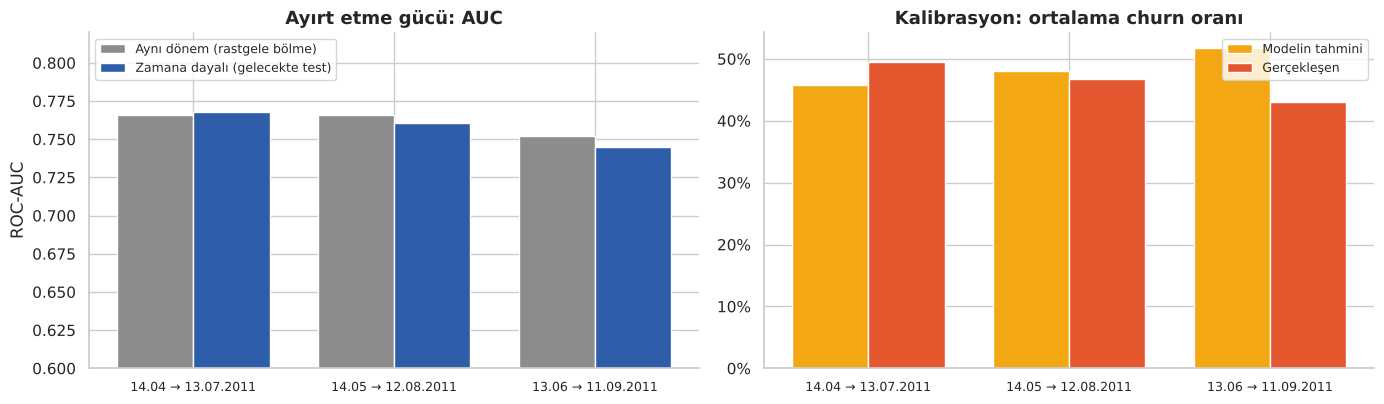

,Zamana dayalı AUC,Aynı dönem CV AUC,Tahmini churn oranı,Gerçek churn oranı,Test müşteri sayısı
Eğitim → Test,,,,,
14.04 → 13.07.2011,0.768,0.766,45.8%,49.5%,"3,025"
14.05 → 12.08.2011,0.760,0.766,48.0%,46.7%,"3,215"
13.06 → 11.09.2011,0.745,0.752,51.7%,43.0%,"3,368"


In [15]:
geri_testler = []
for egitim_kesim in pd.to_datetime(["2011-04-14", "2011-05-14", "2011-06-13"]):
    test_kesim = egitim_kesim + pd.Timedelta(days=TAHMIN_GUN)
    Xa = ozellik_uret(satislar, iadeler, egitim_kesim); ya, _ = hedef_uret(satislar, Xa, egitim_kesim)
    Xb = ozellik_uret(satislar, iadeler, test_kesim);   yb, _ = hedef_uret(satislar, Xb, test_kesim)
    pb = lgb.LGBMClassifier(**lgb_params).fit(Xa, ya).predict_proba(Xb)[:, 1]
    ayni_donem = cross_val_score(lgb.LGBMClassifier(**lgb_params), Xb, yb, cv=cv5, scoring="roc_auc").mean()
    geri_testler.append({"Eğitim → Test": f"{egitim_kesim:%d.%m} → {test_kesim:%d.%m.%Y}",
                         "Zamana dayalı AUC": roc_auc_score(yb, pb), "Aynı dönem CV AUC": ayni_donem,
                         "Tahmini churn oranı": pb.mean(), "Gerçek churn oranı": yb.mean(),
                         "Test müşteri sayısı": len(Xb)})
geri = pd.DataFrame(geri_testler).set_index("Eğitim → Test")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
xx = np.arange(len(geri)); w = .38
axes[0].bar(xx - w/2, geri["Aynı dönem CV AUC"], w, color=PALETTE["gri"], label="Aynı dönem (rastgele bölme)")
axes[0].bar(xx + w/2, geri["Zamana dayalı AUC"], w, color=PALETTE["ana"], label="Zamana dayalı (gelecekte test)")
axes[0].set_xticks(xx); axes[0].set_xticklabels(geri.index, fontsize=9); axes[0].set_ylim(.6, .82)
axes[0].set(title="Ayırt etme gücü: AUC", ylabel="ROC-AUC"); axes[0].legend(loc="upper left", fontsize=9)
axes[1].bar(xx - w/2, geri["Tahmini churn oranı"] * 100, w, color=PALETTE["sari"], label="Modelin tahmini")
axes[1].bar(xx + w/2, geri["Gerçek churn oranı"] * 100, w, color=PALETTE["vurgu"], label="Gerçekleşen")
axes[1].set_xticks(xx); axes[1].set_xticklabels(geri.index, fontsize=9)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].set(title="Kalibrasyon: ortalama churn oranı"); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
geri.style.format({"Zamana dayalı AUC": "{:.3f}", "Aynı dönem CV AUC": "{:.3f}", "Tahmini churn oranı": "{:.1%}",
                   "Gerçek churn oranı": "{:.1%}", "Test müşteri sayısı": "{:,}"})

**Gözlem:**
- **Model zamanda genelleşiyor.** Gelecekteki bir dönemde test edildiğinde AUC (0.745–0.768), aynı dönemdeki rastgele bölme skoruyla neredeyse aynı. Yani model, rastgele bölmenin sağladığı kolaylık sayesinde iyi görünmüyor; sıralama gücü gerçek.
- **Ama kalibrasyon mevsime göre kayıyor.** Üretimin provası olan Haziran → Eylül testinde model churn oranını **%51,7** tahmin etti, gerçekleşen **%43,0** oldu. Yazdan öğrenen model, yılbaşı sezonunda müşterilerin geri döneceğini bilemiyor.
- **Pratik sonuç:** Modelin **"kim daha riskli"** cevabı güvenilir; **"yüzde kaç ihtimalle"** cevabı ise mevsime göre yeniden kalibre edilmeli. Bu, 10. bölümdeki canlı skorlama için önemli bir uyarı.

### 6.4 Mevsim kalibrasyonu

Sıralama gücünü bozmadan olasılıkları düzeltmenin basit ve yerleşik bir yolu var: modelin log-odds değerlerini sabit bir miktar (δ) kaydırmak. Bu dönüşüm sıralamayı değiştirmediği için AUC aynı kalır; sadece olasılıkların genel seviyesi değişir.

$$
p'_i = \sigma\big(\text{logit}(p_i) + \delta\big)
$$

Önce yöntemi geriye dönük testte sınayalım: hedef churn oranı doğru bilinseydi ne kazanırdık ve bu tahmin birkaç puan hatalı olsaydı ne olurdu?

In [16]:
from scipy.special import logit, expit
from scipy.optimize import brentq

def kaydir(p, delta):
    return expit(logit(np.clip(p, 1e-4, 1 - 1e-4)) + delta)

def hedefe_kalibre(p, hedef_oran):
    # Ortalama olasılığı hedef orana eşitleyen δ kaydırması
    delta = brentq(lambda d: kaydir(p, d).mean() - hedef_oran, -5, 5)
    return kaydir(p, delta), delta

# Üretim provası: Haziran'da eğit, Eylül'de test et
e_k, t_k = pd.Timestamp("2011-06-13"), pd.Timestamp("2011-09-11")
Xa = ozellik_uret(satislar, iadeler, e_k); ya, _ = hedef_uret(satislar, Xa, e_k)
Xb = ozellik_uret(satislar, iadeler, t_k); yb, _ = hedef_uret(satislar, Xb, t_k)
pb = lgb.LGBMClassifier(**lgb_params).fit(Xa, ya).predict_proba(Xb)[:, 1]

satir = [{"Senaryo": "Kalibrasyonsuz", "Ort. tahmin": pb.mean(), "Brier (↓)": brier_score_loss(yb, pb), "AUC": roc_auc_score(yb, pb)}]
for hata in [0, -0.05, 0.05]:
    pk, _ = hedefe_kalibre(pb, yb.mean() + hata)
    ad = "Hedef oran doğru biliniyor" if hata == 0 else f"Hedef oran {hata*100:+.0f} puan hatalı"
    satir.append({"Senaryo": ad, "Ort. tahmin": pk.mean(), "Brier (↓)": brier_score_loss(yb, pk), "AUC": roc_auc_score(yb, pk)})
print(f"Gerçekleşen churn oranı (Eylül–Aralık): %{yb.mean()*100:.1f}")
pd.DataFrame(satir).set_index("Senaryo").style.format({"Ort. tahmin": "{:.1%}", "Brier (↓)": "{:.4f}", "AUC": "{:.3f}"})

Gerçekleşen churn oranı (Eylül–Aralık): %43.0


,Ort. tahmin,Brier (↓),AUC
Senaryo,,,
Kalibrasyonsuz,51.7%,0.2084,0.745
Hedef oran doğru biliniyor,43.0%,0.2004,0.745
Hedef oran -5 puan hatalı,38.0%,0.2031,0.745
Hedef oran +5 puan hatalı,48.0%,0.2031,0.745


**Gözlem:**
- Kaydırma **AUC'yi hiç değiştirmiyor** (sıralama aynı), ama ortalama tahmini gerçek orana getirip **Brier skorunu 0.208'den 0.200'e** düşürüyor.
- Daha önemlisi, hedef oran **5 puan hatalı** tahmin edilse bile kalibrasyon yine de kalibrasyonsuz modelden iyi (Brier 0.203). Yani hedef oranı kabaca doğru tahmin etmek yeterli.

**Hedef oranı nereden bileceğiz?** Gelecekteki churn oranını bilemeyiz, ama **geçen yılın aynı dönemine** bakabiliriz. Verideki en temiz mevsim sinyali şu: bir dönemin hemen öncesinde alışveriş yapmış "taze" müşterilerin, o dönem boyunca geri dönmeme oranı. Bu kohort oranı hem eğitim döneminde (Eylül 2011) hem de skorlanacak dönemin geçen yılki karşılığında (Aralık 2010) hesaplanabiliyor. İkisinin log-odds farkını mevsim etkisi (δ) olarak kullanıyoruz:

In [17]:
def kohort_churn(baslangic, gun_once=9, gun=TAHMIN_GUN):
    # Dönem başlangıcından önceki birkaç günde alışveriş yapanların, sonraki 90 günde geri dönmeme oranı
    b = pd.Timestamp(baslangic)
    kohort = satislar[(satislar["InvoiceDate"] >= b - pd.Timedelta(days=gun_once)) & (satislar["InvoiceDate"] < b)]["CustomerID"].unique()
    sonra = satislar[(satislar["InvoiceDate"] >= b) & (satislar["InvoiceDate"] < b + pd.Timedelta(days=gun))]["CustomerID"].unique()
    return 1 - np.isin(kohort, sonra).mean(), len(kohort)

egitim_kohort, n1 = kohort_churn(KESIM)                          # modelin öğrendiği mevsim (Eylül–Aralık 2011)
gecen_yil_kohort, n2 = kohort_churn("2010-12-10")                 # skorlanacak dönemin geçen yılki karşılığı (Aralık–Mart)
MEVSIM_DELTA = logit(gecen_yil_kohort) - logit(egitim_kohort)
print(f"Taze müşteri kohortu churn oranı — Eylül 2011: %{egitim_kohort*100:.1f} (n={n1}),  Aralık 2010: %{gecen_yil_kohort*100:.1f} (n={n2})")
print(f"Mevsim kaydırması δ = {MEVSIM_DELTA:+.2f} log-odds  →  Aralık–Mart döneminde churn eğilimi belirgin şekilde daha yüksek")

Taze müşteri kohortu churn oranı — Eylül 2011: %21.0 (n=338),  Aralık 2010: %40.4 (n=572)
Mevsim kaydırması δ = +0.94 log-odds  →  Aralık–Mart döneminde churn eğilimi belirgin şekilde daha yüksek


**Gözlem:** Taze müşterilerin geri dönmeme oranı Aralık–Mart döneminde, Eylül–Aralık dönemine göre neredeyse iki kat (%40 vs %21). Bu, EDA'daki tabloyla da tutarlı: yılbaşı sonrası aylarda aktif müşteri sayısı belirgin şekilde düşüyor. Canlı skorlamada (10. bölüm) olasılıkları bu δ kadar kaydırıyoruz.

> **Varsayım ve sınırlılık:** Bu yöntem mevsim etkisinin log-odds üzerinde tüm müşteriler için aynı olduğunu ve tek bir geçmiş yılın temsil edici olduğunu varsayıyor. Veri bir yıl olduğu için kaydırmanın kendisi geriye dönük test edilemiyor; ama mekanizma yukarıda test edildi ve hedef orandaki makul hatalara karşı dayanıklı.

## 7. Açıklanabilirlik: Model Neden Böyle Düşünüyor?

Bir pazarlama müdürü "bu müşteri neden riskli?" diye sorduğunda cevap verebilmeliyiz. SHAP değerleri her özelliğin her tahmine katkısını ölçer.

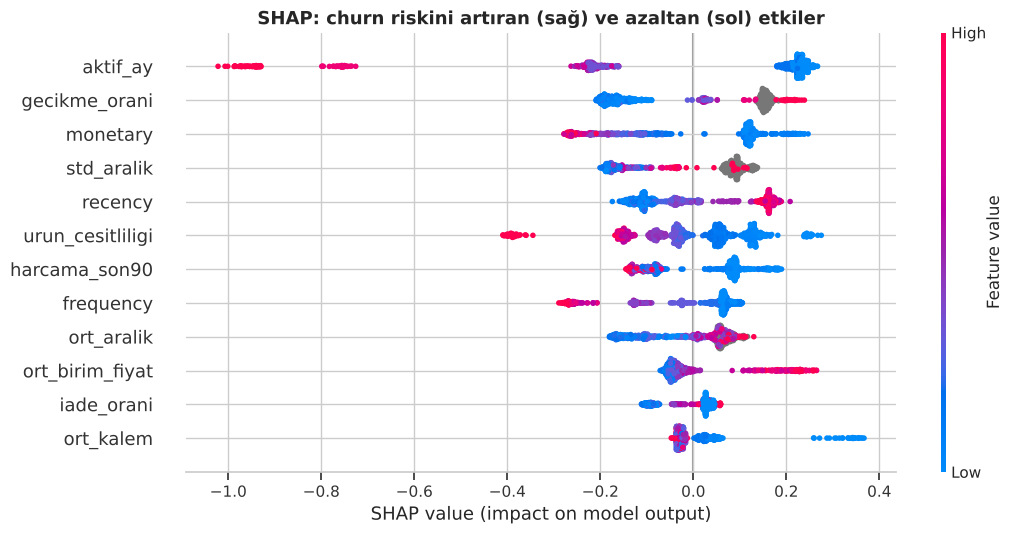

In [18]:
explainer = shap.TreeExplainer(clf)
shap_te = explainer.shap_values(X_te)
if isinstance(shap_te, list): shap_te = shap_te[1]

plt.figure()
shap.summary_plot(shap_te, X_te, max_display=12, show=False, plot_size=(11, 5.5))
plt.title("SHAP: churn riskini artıran (sağ) ve azaltan (sol) etkiler", fontweight="bold")
plt.tight_layout(); plt.show()

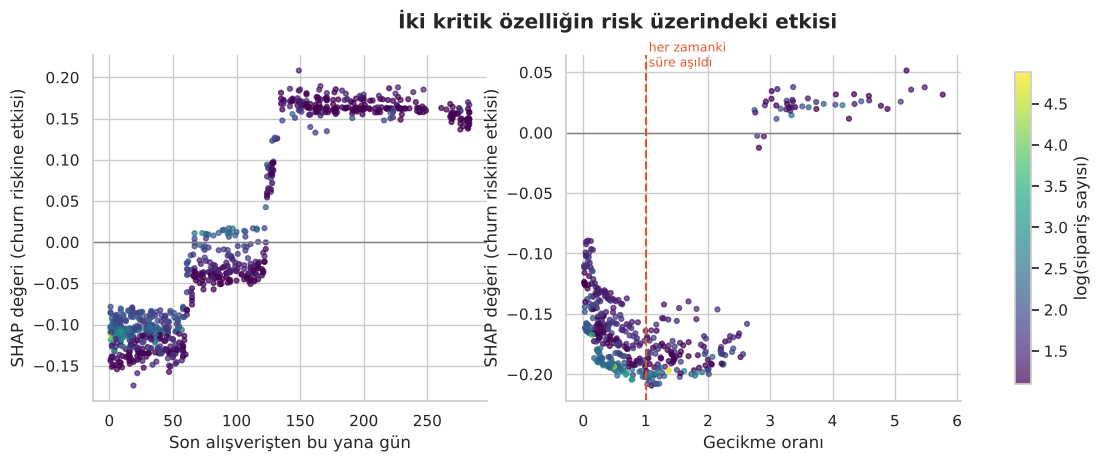

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, xlab in [(axes[0], "recency", "Son alışverişten bu yana gün"),
                      (axes[1], "gecikme_orani", "Gecikme oranı")]:
    i = OZELLIKLER.index(col)
    sinir = 6 if col == "gecikme_orani" else X_te[col].max()
    mask = X_te[col].notna() & (X_te[col] <= sinir)
    sc = ax.scatter(X_te.loc[mask, col], shap_te[mask.values, i], c=np.log1p(X_te.loc[mask, "frequency"]),
                    cmap="viridis", s=12, alpha=.7)
    ax.axhline(0, color="gray", lw=1)
    ax.set(xlabel=xlab, ylabel="SHAP değeri (churn riskine etkisi)")
    if col == "gecikme_orani": ax.axvline(1, color=PALETTE["vurgu"], ls="--", lw=1.5); ax.text(1.05, ax.get_ylim()[1]*0.85, "her zamanki\nsüre aşıldı", color=PALETTE["vurgu"], fontsize=9)
cb = plt.colorbar(sc, ax=axes, shrink=.9); cb.set_label("log(sipariş sayısı)")
plt.suptitle("İki kritik özelliğin risk üzerindeki etkisi", fontweight="bold"); plt.show()

**İçgörüler:**
1. **Süreklilik en güçlü koruyucu:** Modelin en önemli özelliği `aktif_ay`. Çok sayıda farklı ayda alışveriş yapmış müşterilerde risk dramatik biçimde düşüyor (grafikteki uzun sol kuyruk). Bir müşterinin toplam ne kadar harcadığından çok, **ne kadar düzenli** geldiği önemli.
2. **Gecikme oranı** ilginç bir şekil çiziyor: risk, oran 1'e yaklaştığında en düşük (müşteri tam "sıradaki alışveriş zamanında"). 1'i geçtikten sonra risk yeniden tırmanıyor ve **kendi ritminin yaklaşık 3 katı** sessiz kalan müşteriler net biçimde riskli bölgeye geçiyor. Bu, tüm müşterilere aynı "60 gün sessizse kampanya gönder" kuralını uygulamaktan çok daha akıllı, kişiye özel bir tetikleyici.
3. **Recency** basamaklı bir etki gösteriyor: ilk ~60 gün risk düşük, sonrasında artmaya başlıyor ve ~130. günde zirveye ulaşıp sabitleniyor. Yani geri kazanım için en verimli pencere **60–130. günler** arası: daha sonrası çoğu zaman geç kalınmış demek.
4. **Son 90 günde düşük harcama** ve **yüksek iade oranı** riski artıran diğer sinyaller; iade oranı memnuniyetsizliğin erken habercisi.

## 8. Değer Modeli: Giderse Ne Kaybederiz?

Churn olasılığı tek başına yetmez: £20 harcayan bir müşteriyi kaybetmekle £5.000 harcayanı kaybetmek aynı şey değil. Bu yüzden **iki aşamalı (hurdle) bir yapı** kuruyoruz:

$$
\mathbb{E}[\text{90 günlük gelir}] = \underbrace{\big(1 - P(\text{churn})\big)}_{\text{kalır mı? (model 1)}} \times \underbrace{\mathbb{E}[\text{gelir} \mid \text{kalır}]}_{\text{kalırsa ne harcar? (model 2)}}
$$

Model 2'yi sadece **kalan müşteriler** üzerinde eğitiyoruz. Böylece "bu müşteri kalsaydı bize ne kazandırırdı?" sorusunun cevabı, yani **kaybedilecek değer**, doğrudan elimizde oluyor.

Harcama çok çarpık: müşterilerin çoğu birkaç yüz £ bırakırken birkaç toptancı on binlerce £ harcıyor. Bu yüzden kayıp fonksiyonu seçimi kritik (bkz. 8.1). Final modelde **Tweedie (p = 1.2)** kaybı kullanıyoruz.

**Kıyaslama ölçütleri:**
- **Naif:** "Son 90 günde ne harcadıysa yine onu harcar."
- **Klasik CLTV (BG-NBD × Gamma-Gamma):** Önceki CLTV projemdeki olasılıksal model. Satın alma sıklığını BG-NBD, sepet büyüklüğünü Gamma-Gamma ile tahmin ediyor. ML yaklaşımının klasik yöntemi gerçekten geçip geçmediğini görmek için en dürüst ölçüt bu.

In [20]:
from lifetimes import BetaGeoFitter, GammaGammaFitter

def btyd_cltv(satis, kesim, gun=TAHMIN_GUN):
    # Klasik CLTV: BG-NBD (işlem sayısı) × Gamma-Gamma (ortalama sepet). Haftalık birimlerle.
    s = satis[satis["InvoiceDate"] < kesim]
    gunluk = s.assign(d=s["InvoiceDate"].dt.normalize()).groupby(["CustomerID", "d"])["Tutar"].sum().reset_index()
    g = gunluk.groupby("CustomerID")
    o = pd.DataFrame({"frequency": g["d"].nunique() - 1,
                      "recency": (g["d"].max() - g["d"].min()).dt.days / 7,
                      "T": (kesim - g["d"].min()).dt.days / 7,
                      "monetary": g["Tutar"].mean()})
    bg = BetaGeoFitter(penalizer_coef=0.1).fit(o["frequency"], o["recency"], o["T"])
    tekrar = o[o["frequency"] > 0]
    gg = GammaGammaFitter(penalizer_coef=0.01).fit(tekrar["frequency"], tekrar["monetary"])
    islem = bg.conditional_expected_number_of_purchases_up_to_time(gun / 7, o["frequency"], o["recency"], o["T"])
    sepet = gg.conditional_expected_average_profit(o["frequency"].clip(lower=1), o["monetary"])
    return (islem * sepet).rename("btyd_cltv"), bg.params_

btyd, bg_params = btyd_cltv(satislar, KESIM)
print("BG-NBD parametreleri:", {k: round(v, 3) for k, v in bg_params.items()})

kalan_tr = yc_tr.values == 0
kalan_te = yc_te.values == 0
tw = dict(objective="tweedie", tweedie_variance_power=1.2)
reg_gamma = lgb.LGBMRegressor(objective="gamma", **lgb_ilk).fit(X_tr[kalan_tr], yg_tr[kalan_tr])   # ilk sürüm
reg = lgb.LGBMRegressor(**tw, **lgb_ilk).fit(X_tr[kalan_tr], yg_tr[kalan_tr])                      # final

kalirsa_deger = reg.predict(X_te)                 # model 2: kalırsa beklenen 90 günlük gelir
gelir_tahmin = (1 - p_lgb) * kalirsa_deger        # hurdle: beklenen 90 günlük gelir
gelir_gamma = (1 - p_lgb) * reg_gamma.predict(X_te)
naif = X_te["harcama_son90"].values
klasik = btyd.reindex(X_te.index).values

adaylar = {"Naif (son 90 gün)": naif, "Klasik CLTV (BG-NBD × GG)": klasik,
           "Hurdle — Gamma (ilk sürüm)": gelir_gamma, "Hurdle — Tweedie (final)": gelir_tahmin}
tablo = pd.DataFrame({
    "MAE (£)": [mean_absolute_error(yg_te, v) for v in adaylar.values()],
    "R²": [r2_score(yg_te, v) for v in adaylar.values()],
    "Toplam tahmin (£)": [v.sum() for v in adaylar.values()],
}, index=adaylar.keys())
print(f"Test setinde gerçekleşen toplam 90 günlük gelir: £{yg_te.sum():,.0f}")
tablo.style.format({"MAE (£)": "{:,.0f}", "R²": "{:.3f}", "Toplam tahmin (£)": "{:,.0f}"}).highlight_min(subset=["MAE (£)"], color="#d4edda").highlight_max(subset=["R²"], color="#d4edda")

BG-NBD parametreleri: {'r': 0.527, 'alpha': 6.922, 'a': 0.0, 'b': 0.0}


Test setinde gerçekleşen toplam 90 günlük gelir: £618,798


,MAE (£),R²,Toplam tahmin (£)
Naif (son 90 gün),564,0.654,"436,276"
Klasik CLTV (BG-NBD × GG),539,0.522,"390,396"
Hurdle — Gamma (ilk sürüm),546,0.564,"529,040"
Hurdle — Tweedie (final),556,0.546,"523,129"


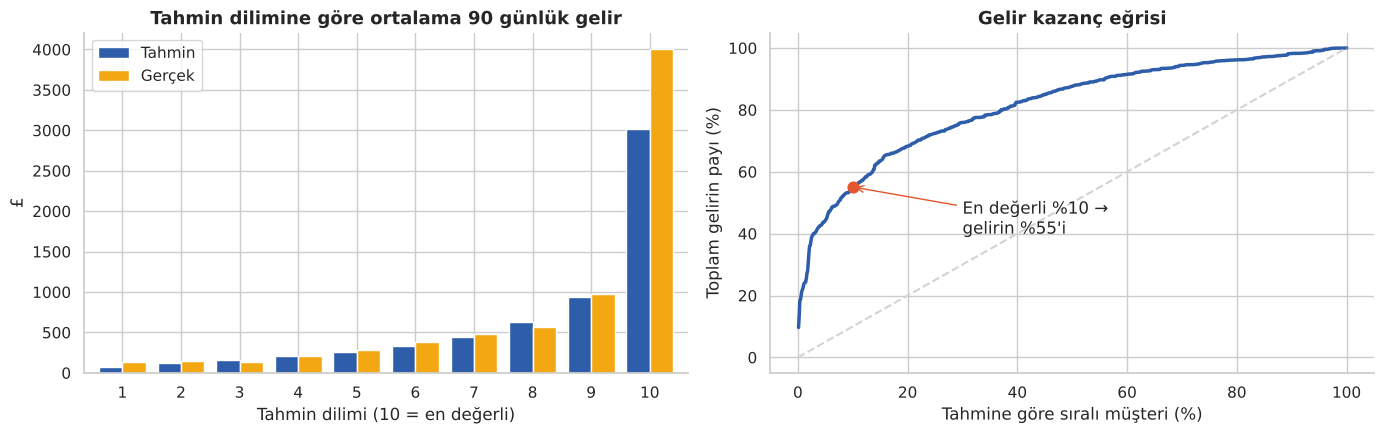

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dilim = pd.qcut(pd.Series(gelir_tahmin).rank(method="first"), 10, labels=range(1, 11))
kars = pd.DataFrame({"dilim": dilim.values, "Tahmin": gelir_tahmin, "Gerçek": yg_te.values}).groupby("dilim", observed=True).mean()
kars.plot.bar(ax=axes[0], color=[PALETTE["ana"], PALETTE["sari"]], width=.8)
axes[0].set(title="Tahmin dilimine göre ortalama 90 günlük gelir", xlabel="Tahmin dilimi (10 = en değerli)", ylabel="£")
axes[0].tick_params(axis="x", rotation=0)

pay = np.sort(yg_te.values[np.argsort(-gelir_tahmin)])
kum = np.cumsum(yg_te.values[np.argsort(-gelir_tahmin)]) / yg_te.sum()
axes[1].plot(np.arange(1, len(kum) + 1) / len(kum) * 100, kum * 100, lw=2.5, color=PALETTE["ana"])
axes[1].plot([0, 100], [0, 100], "--", color="lightgray")
k = int(.1 * len(kum))
axes[1].scatter([10], [kum[k] * 100], color=PALETTE["vurgu"], zorder=5, s=60)
axes[1].annotate(f"En değerli %10 →\ngelirin %{kum[k]*100:.0f}'i", (10, kum[k] * 100), xytext=(30, 40),
                 arrowprops=dict(arrowstyle="->", color=PALETTE["vurgu"]))
axes[1].set(title="Gelir kazanç eğrisi", xlabel="Tahmine göre sıralı müşteri (%)", ylabel="Toplam gelirin payı (%)")
plt.tight_layout(); plt.show()

**İlk bakış:** Tek test setinde dört yöntem birbirine çok yakın, hatta naif yöntem R²'de önde görünüyor. Ama burada dikkatli olmak gerek: 842 müşterilik bir sette birkaç dev toptancının tahmini bütün R²'yi belirleyebiliyor. Hangi yöntemin gerçekten iyi olduğunu tek bir bölmeye bakarak söyleyemeyiz.

### 8.1 Değer modeli: Sağlam karşılaştırma

Churn modelinde yaptığımız gibi, değer modelini de **yalnızca eğitim müşterileri** üzerinde, **25 farklı bölmede** seçiyoruz (test seti yukarıdaki tek seferlik kontrol dışında kullanılmıyor). Her bölmede churn modeli ve değer modeli sıfırdan eğitiliyor ve dört yöntem aynı müşteriler üzerinde yarışıyor.

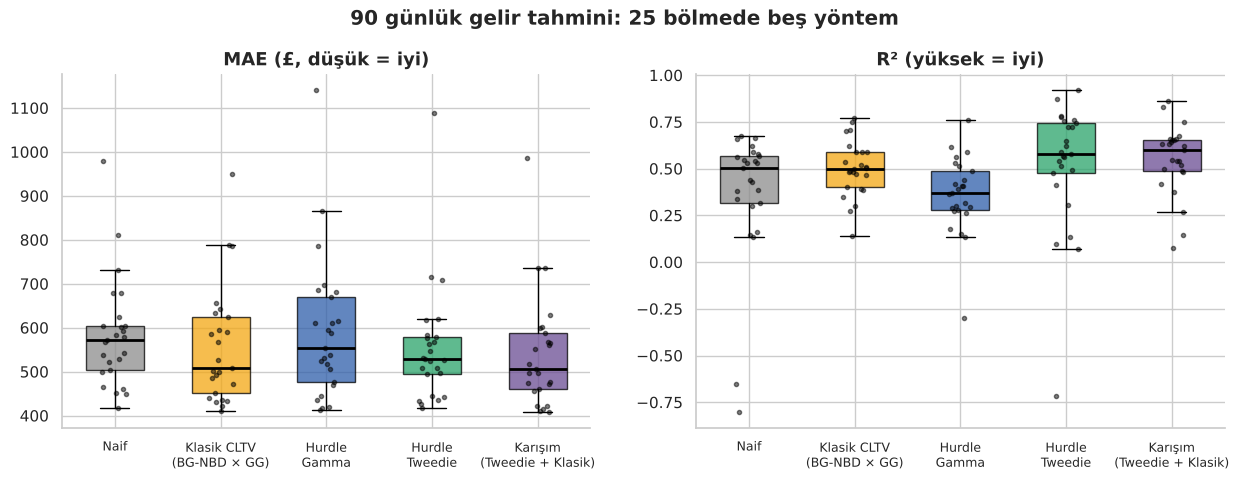

,Ort. MAE (£),Ort. R²,Karışımdan iyi olduğu bölme (MAE)
Naif,583,0.365,3
Klasik CLTV (BG-NBD × GG),557,0.500,6
Hurdle Gamma,592,0.362,2
Hurdle Tweedie,556,0.518,9
Karışım (Tweedie + Klasik),542,0.550,0


In [22]:
bolmeler_d = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=11).split(X_tr, yc_tr))
btyd_tum = btyd.reindex(X_tr.index).values
yc_v, yg_v = yc_tr.values, yg_tr.values
sonuclar = {k: [] for k in ["Naif", "Klasik CLTV\n(BG-NBD × GG)", "Hurdle\nGamma", "Hurdle\nTweedie", "Karışım\n(Tweedie + Klasik)"]}

for a, b in bolmeler_d:
    p = lgb.LGBMClassifier(**lgb_params).fit(X_tr.iloc[a], yc_v[a]).predict_proba(X_tr.iloc[b])[:, 1]
    kal = yc_v[a] == 0
    h_tw = (1 - p) * lgb.LGBMRegressor(**tw, **lgb_ilk).fit(X_tr.iloc[a][kal], yg_v[a][kal]).predict(X_tr.iloc[b])
    tahminler = [X_tr.iloc[b]["harcama_son90"].values, btyd_tum[b],
                 (1 - p) * lgb.LGBMRegressor(objective="gamma", **lgb_ilk).fit(X_tr.iloc[a][kal], yg_v[a][kal]).predict(X_tr.iloc[b]),
                 h_tw, 0.5 * h_tw + 0.5 * btyd_tum[b]]   # karışım: ağırlık önceden sabit (ayar yok)
    for k, t in zip(sonuclar, tahminler):
        sonuclar[k].append((mean_absolute_error(yg_v[b], t), r2_score(yg_v[b], t)))
sonuclar = {k: np.array(v) for k, v in sonuclar.items()}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
renkler = [PALETTE["gri"], PALETTE["sari"], PALETTE["ana"], PALETTE["yesil"], "#6A4C93"]
for ax, j, baslik in [(axes[0], 0, "MAE (£, düşük = iyi)"), (axes[1], 1, "R² (yüksek = iyi)")]:
    veri = [v[:, j] for v in sonuclar.values()]
    bp = ax.boxplot(veri, patch_artist=True, widths=.55, medianprops=dict(color="black", lw=2), showfliers=False)
    for kutu, r in zip(bp["boxes"], renkler): kutu.set_facecolor(r); kutu.set_alpha(.75)
    for i, v in enumerate(veri):
        ax.scatter(np.full(len(v), i + 1) + np.random.default_rng(i).uniform(-.12, .12, len(v)), v, color="black", s=9, alpha=.5, zorder=3)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels(sonuclar.keys(), fontsize=9); ax.set_title(baslik)
plt.suptitle("90 günlük gelir tahmini: 25 bölmede beş yöntem", fontweight="bold", y=1.02); plt.show()

ozet_d = pd.DataFrame({"Ort. MAE (£)": [v[:, 0].mean() for v in sonuclar.values()],
                       "Ort. R²": [v[:, 1].mean() for v in sonuclar.values()],
                       "Karışımdan iyi olduğu bölme (MAE)": [(v[:, 0] < sonuclar["Karışım\n(Tweedie + Klasik)"][:, 0]).sum() for v in sonuclar.values()]},
                      index=[k.replace("\n", " ") for k in sonuclar])
ozet_d.style.format({"Ort. MAE (£)": "{:,.0f}", "Ort. R²": "{:.3f}"})

**Gözlem:**
- **Tweedie hurdle modeli, eski Gamma modelini ve naif yöntemi açıkça geçiyor** (R² 0.52'ye karşı 0.36 ve 0.37) ve hatası en düşük olan model.
- **Klasik CLTV ile ise başa baş** (R² 0.50, MAE neredeyse aynı). Bu dürüst ve önemli bir sonuç: 90 günlük *gelir tahmininde* ML yaklaşımı klasik BG-NBD × Gamma-Gamma'yı ancak yakalayabiliyor. Hurdle yapının asıl avantajı doğrulukta değil, **kalırsa değeri ayrıca vermesinde**: kampanya kararı tam olarak bu sayıya dayanıyor ve klasik model bunu veremiyor (aşağıya bakın).
- **İkisini birleştirmek ikisinden de iyi.** Hurdle Tweedie ile klasik CLTV'nin basit ortalaması (ağırlık önceden %50 olarak sabitlendi, ayar yapılmadı) R²'yi **0.55**'e çıkarıyor ve en düşük hatayı veriyor (MAE £542). İki yöntem farklı mantıkla çalıştığı için hataları birbirini kısmen dengeliyor. Bu yüzden **90 günlük gelir tahmini** için final yöntem bu karışım. Kampanya kararı ise "kalırsa değer" gerektirdiği için hurdle modelin kendisini kullanmaya devam ediyor.
- **Kayıp fonksiyonu seçimi algoritmadan daha önemli çıktı.** İlk sürümdeki Gamma kaybı, büyük harcamaları göreceli hata olarak değerlendirdiği için dev müşterilerin hatasını önemsizleştiriyordu; bu yüzden klasik CLTV'nin gerisinde kalıyordu. Poisson'a yakın davranan Tweedie (p = 1.2) bu müşterilere hak ettikleri ağırlığı veriyor. Denediğim diğer kayıplar (L2, Huber, p = 1.5–1.8) daha kötüydü.
- **BG-NBD'den ilginç bir bulgu:** Model, müşteri kaybı parametrelerini (a, b) sıfıra indiriyor; yani 9 aylık gözlem penceresinde kimin "öldüğünü" ayırt edemiyor ve herkesi hâlâ aktif sayıyor. Klasik yöntemin kısa veri geçmişindeki bu zayıflığı, churn olasılığını ayrı bir modelle tahmin eden hurdle yapısının neden daha iyi çalıştığını açıklıyor.
- Hurdle yapının naif yöntemin **hiç veremeyeceği** bir bilgisi daha var: son 90 günde alışveriş yapmamış (naif tahmine göre değeri £0 olan) bir müşterinin **kalırsa ne kazandıracağını** biliyoruz. Kampanya kararı tam olarak bu sayıya dayanıyor.

## 9. Kampanya ROI Simülasyonu: Bütçeyi Kime Harcamalı?

Şimdi iki modeli birleştirip asıl iş sorusunu cevaplıyoruz. Her müşteri için **kampanyanın beklenen net kârı**:

$$
\text{Beklenen net kâr}_i = \underbrace{P(\text{churn})_i}_{\text{model 1}} \times \underbrace{\text{Değer}_i}_{\text{model 2}} \times \underbrace{s}_{\text{ikna oranı}} \times \underbrace{m}_{\text{kâr marjı}} - \underbrace{c}_{\text{maliyet}}
$$

**Varsayımlar** (gerçek projede A/B testinden ölçülür, burada ayarlanabilir parametreler):
- **İkna oranı (s) = %15:** Kampanya, gidecek müşterilerin %15'ini tutuyor.
- **Kâr marjı (m) = %30:** Kurtarılan gelirin kâra dönen kısmı.
- **Kampanya maliyeti (c) = £10:** Müşteri başına indirim kuponu + iletişim maliyeti (kuponu zaten kalacak müşteriler de kullanır).

**Değerlendirmeyi döngüsellikten arındırmak:** Burada ince bir tuzak var. Stratejileri değer modeliyle sıralayıp yine değer modeliyle puanlarsak, değere göre sıralayan strateji kendi tahminini "doğrulamış" olur. Bunu önlemek için kurtarılan müşterinin değerini modelden **bağımsız** bir vekille ölçüyoruz: müşterinin geçmiş harcama hızı (toplam harcama ÷ en az 90 gün olmak üzere müşteri yaşı × 90 gün). Değer modeli bu sayıyı hiç görmedi; sadece sıralamada kullanılıyor.

**Adil kıyas: eşit bütçe.** Her strateji için "optimum noktayı" sonradan seçmek iyimser bir sonuç verir. Bunun yerine kuralı önceden sabitliyoruz: bu proje **beklenen kâr > 0** olan müşterileri hedefliyor (k müşteri) ve diğer stratejilere de **aynı sayıda müşteri** veriliyor.

**Belirsizlik:** Test setini 2.000 kez yeniden örnekleyerek (bootstrap) her stratejinin kârı için **%95 güven aralığı** hesaplıyoruz.

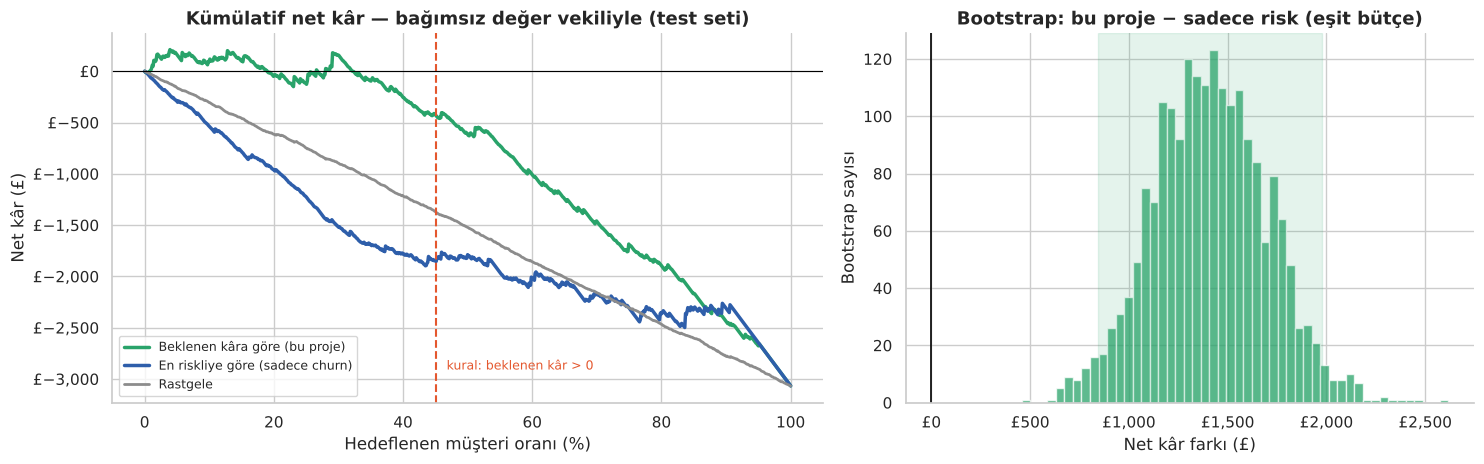

Hedeflenen müşteri (k): 380 / 842
Bu proje − sadece risk, bağımsız vekil: medyan £1,406  %95 GA [£841 ; £1,976]  |  fark > 0 olasılığı: %100.0
Bu proje − sadece risk, model değeri:   medyan £1,090  %95 GA [£480 ; £1,727]  |  fark > 0 olasılığı: %100.0


,Hedeflenen müşteri,Net kâr — Bağımsız vekil,Net kâr — Model değeri
Strateji,,,
Herkese gönder,842,"£-3,083 [-3,782 ; -2,285]","£1,269 [302 ; 2,279]"
Rastgele k müşteri,380,"£-1,391 [-1,707 ; -1,031]","£573 [136 ; 1,029]"
En riskli k müşteri,380,"£-1,856 [-2,190 ; -1,517]","£1,590 [979 ; 2,219]"
Beklenen kâr > 0 (bu proje),380,"£-448 [-1,055 ; 155]","£2,684 [1,894 ; 3,507]"


In [23]:
S_IKNA, MARJ, MALIYET = 0.15, 0.30, 10.0
p_churn = p_lgb
beklenen_kar = p_churn * kalirsa_deger * S_IKNA * MARJ - MALIYET

# Bağımsız değer vekili: geçmiş harcama hızından 90 günlük değer (değer modelinden bağımsız)
vekil_deger = (X_te["monetary"] / X_te["tenure"].clip(lower=TAHMIN_GUN) * TAHMIN_GUN).values
fayda = {"Bağımsız vekil": yc_te.values * vekil_deger * S_IKNA * MARJ - MALIYET,
         "Model değeri": yc_te.values * kalirsa_deger * S_IKNA * MARJ - MALIYET}

n = len(p_churn)
secim_kar = beklenen_kar > 0
k = int(secim_kar.sum())
secim_risk = np.zeros(n, bool); secim_risk[np.argsort(-p_churn)[:k]] = True
politikalar = {"Herkese gönder": np.ones(n, bool), "Rastgele k müşteri": None,
               "En riskli k müşteri": secim_risk, "Beklenen kâr > 0 (bu proje)": secim_kar}

B = 2000
idx = np.random.default_rng(RANDOM_STATE).integers(0, n, (B, n))
boot = {}
for olcut, f in fayda.items():
    for ad, sec in politikalar.items():
        boot[(olcut, ad)] = f[idx].mean(1) * k if sec is None else (f[idx] * sec[idx]).sum(1)

satirlar = []
for ad, sec in politikalar.items():
    r = {"Strateji": ad, "Hedeflenen müşteri": n if ad == "Herkese gönder" else k}
    for olcut in fayda:
        b_ = boot[(olcut, ad)]
        r[f"Net kâr — {olcut}"] = f"£{np.median(b_):,.0f}  [{np.percentile(b_, 2.5):,.0f} ; {np.percentile(b_, 97.5):,.0f}]"
    satirlar.append(r)
ozet = pd.DataFrame(satirlar).set_index("Strateji")

fark_v = boot[("Bağımsız vekil", "Beklenen kâr > 0 (bu proje)")] - boot[("Bağımsız vekil", "En riskli k müşteri")]
fark_m = boot[("Model değeri", "Beklenen kâr > 0 (bu proje)")] - boot[("Model değeri", "En riskli k müşteri")]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
f = fayda["Bağımsız vekil"]
egri = lambda skor: np.concatenate([[0], np.cumsum(f[np.argsort(-skor)])])
xs = np.arange(n + 1) / n * 100
axes[0].plot(xs, egri(beklenen_kar), lw=2.5, color=PALETTE["yesil"], label="Beklenen kâra göre (bu proje)")
axes[0].plot(xs, egri(p_churn), lw=2.5, color=PALETTE["ana"], label="En riskliye göre (sadece churn)")
axes[0].plot(xs, np.mean([egri(np.random.default_rng(i).random(n)) for i in range(30)], axis=0), lw=2, color=PALETTE["gri"], label="Rastgele")
axes[0].axvline(k / n * 100, color=PALETTE["vurgu"], ls="--", lw=1.5)
axes[0].text(k / n * 100 + 1, axes[0].get_ylim()[0] * 0.9 if axes[0].get_ylim()[0] < 0 else 0, " kural: beklenen kâr > 0", color=PALETTE["vurgu"], fontsize=9)
axes[0].axhline(0, color="black", lw=.8)
axes[0].set(title="Kümülatif net kâr — bağımsız değer vekiliyle (test seti)", xlabel="Hedeflenen müşteri oranı (%)", ylabel="Net kâr (£)")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}")); axes[0].legend(fontsize=9)

axes[1].hist(fark_v, bins=50, color=PALETTE["yesil"], alpha=.75)
lo, hi = np.percentile(fark_v, [2.5, 97.5])
axes[1].axvspan(lo, hi, color=PALETTE["yesil"], alpha=.12); axes[1].axvline(0, color="black", lw=1.2)
axes[1].set(title="Bootstrap: bu proje − sadece risk (eşit bütçe)", xlabel="Net kâr farkı (£)", ylabel="Bootstrap sayısı")
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
plt.tight_layout(); plt.show()

print(f"Hedeflenen müşteri (k): {k} / {n}")
print(f"Bu proje − sadece risk, bağımsız vekil: medyan £{np.median(fark_v):,.0f}  %95 GA [£{lo:,.0f} ; £{hi:,.0f}]  |  fark > 0 olasılığı: %{(fark_v > 0).mean()*100:.1f}")
print(f"Bu proje − sadece risk, model değeri:   medyan £{np.median(fark_m):,.0f}  %95 GA [£{np.percentile(fark_m, 2.5):,.0f} ; £{np.percentile(fark_m, 97.5):,.0f}]  |  fark > 0 olasılığı: %{(fark_m > 0).mean()*100:.1f}")
ozet

**Bu projenin ana bulgusu (dürüst versiyonu):**
- **Göreli üstünlük sağlam.** Aynı bütçeyle (380 müşteri), risk × değer kuralı, sadece riske göre hedeflemekten **her iki değerlendirmede de** daha fazla kâr getiriyor: bağımsız vekille **+£1.406** (%95 GA: £841 – £1.976), model değeriyle **+£1.090** (%95 GA: £480 – £1.727). 2.000 bootstrap örneğinin tamamında fark pozitif.
- **Mutlak kârlılık ise varsayımlara bağlı.** Bağımsız vekille ölçüldüğünde, mevcut varsayımlar altında (%15 ikna, £10 maliyet) kupon kampanyası en iyi hedeflemeyle bile **yaklaşık başa baş** (−£448, GA: −£1.055 ile +£155). Herkese göndermek ise açık bir zarar (−£3.083). Model değeriyle ölçüldüğünde aynı kural kârlı (+£2.684). Vekil, Eylül–Aralık sezonundaki yaklaşık 2 kat gelir artışını hesaba katmadığı için **muhafazakâr**; gerçek değer büyük ihtimalle ikisinin arasında.
- **Pratik sonuç:** "Kimi hedeflemeliyiz?" sorusuna verdiğimiz cevap güvenilir. "Kampanya toplamda ne kazandırır?" sorusu ise ancak gerçek ikna oranını ölçen bir **A/B testiyle** kesinleşir.

### Duyarlılık analizi: Varsayımlar değişirse?

İkna oranı ve maliyet tahmindir. Sonucun bu varsayımlara ne kadar duyarlı olduğunu görmek için, sabit kuralı (**beklenen kâr > 0**) farklı varsayımlar altında bağımsız değer vekiliyle değerlendiriyoruz:

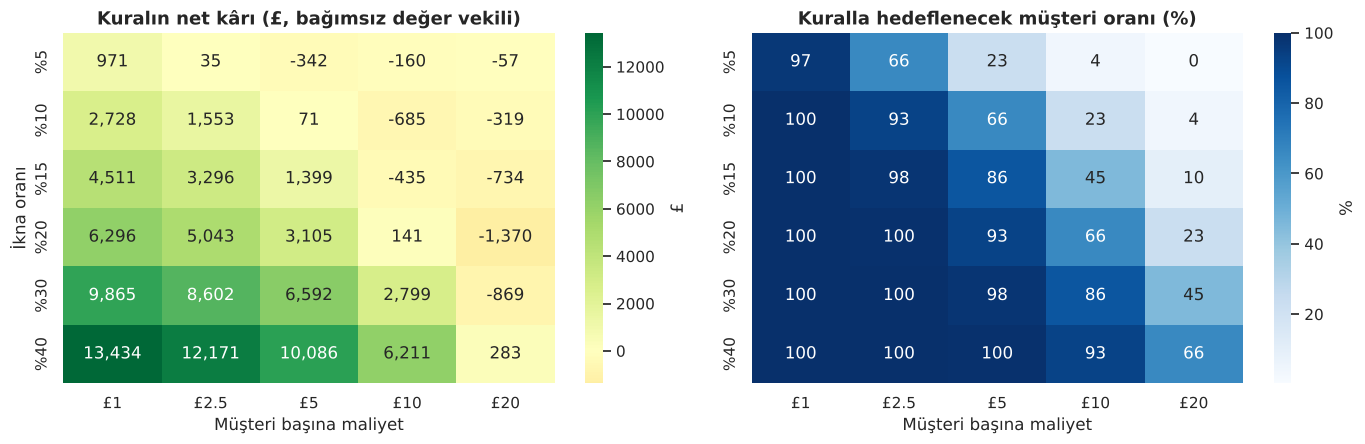

In [24]:
ikna_list = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
maliyet_list = [1, 2.5, 5, 10, 20]
kar_tablo = pd.DataFrame(index=[f"%{int(s*100)}" for s in ikna_list], columns=[f"£{c:g}" for c in maliyet_list], dtype=float)
hedef_tablo = kar_tablo.copy()
for s_ in ikna_list:
    for c in maliyet_list:
        bk = p_churn * kalirsa_deger * s_ * MARJ - c
        gf = yc_te.values * vekil_deger * s_ * MARJ - c
        kar_tablo.loc[f"%{int(s_*100)}", f"£{c:g}"] = (gf * (bk > 0)).sum()
        hedef_tablo.loc[f"%{int(s_*100)}", f"£{c:g}"] = (bk > 0).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.heatmap(kar_tablo, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, ax=axes[0], cbar_kws={"label": "£"})
axes[0].set(title="Kuralın net kârı (£, bağımsız değer vekili)", xlabel="Müşteri başına maliyet", ylabel="İkna oranı")
sns.heatmap(hedef_tablo, annot=True, fmt=".0f", cmap="Blues", ax=axes[1], cbar_kws={"label": "%"})
axes[1].set(title="Kuralla hedeflenecek müşteri oranı (%)", xlabel="Müşteri başına maliyet", ylabel="")
plt.tight_layout(); plt.show()

**Gözlem:** Muhafazakâr vekille bile tablo net bir yol gösteriyor: **ucuz kanallar** (müşteri başına £1–5) makul her ikna oranında kârlı; **£10'luk kupon** ise ikna oranı en az ~%20 olduğunda kâr getiriyor. Bu yüzden 10. bölümde tek bir kampanya yerine, her müşteriye kendi değerine uygun maliyette bir kanal seçen bir karar mantığı kuruyoruz. Kural aynı kalıyor: **beklenen kâr > 0 ise dokun**.

## 10. Canlı Skorlama: Bugün Kimi Aramalıyız?

Şimdiye kadar geçmişte doğruladık. Gerçek hayatta model **bugünkü** veriyle çalışacak. Doğruladığımız modelleri tüm müşterilerle yeniden eğitiyor, ardından kesim tarihini verinin son gününe kaydırıp bugünkü özellikleri hesaplıyor ve tüm müşterileri skorluyoruz.

**Tek karar mantığı:** Aksiyonlar artık keyfi eşiklerle değil, kampanya bölümündeki aynı ekonomik kuralla belirleniyor. Üç iletişim kanalının her birinin kendi maliyeti ve tahmini ikna oranı var. Her müşteri için **beklenen kârı en yüksek kanal** seçiliyor; hiçbir kanal kârlı değilse müşteriye dokunulmuyor.

| Kanal | Maliyet | İkna oranı (varsayım) |
|---|---|---|
| 🔴 Kişisel arama + özel teklif | £25 | %25 |
| 🟠 Kişiselleştirilmiş kupon | £10 | %15 |
| 🟡 Otomatik e-posta | £0,5 | %3 |

> ⚠️ **Mevsim kayması:** Model Eylül–Aralık (yılbaşı sezonu) penceresinden öğrendi, bu liste ise Aralık–Mart (düşük sezon) için üretiliyor. Bu yüzden olasılıklara 6.4'teki **mevsim kalibrasyonunu** uyguluyoruz; ham olasılıklar da karşılaştırma için listede duruyor. Kalibrasyon sıralamayı değiştirmez, sadece olasılıkların ve kâr tutarlarının seviyesini düzeltir. Kaydırma tek bir geçmiş yıla dayandığı için tutarlar yine de **yaklaşık** kabul edilmeli; üretimde model her ay güncel veriyle yeniden eğitilmeli.

In [25]:
# Eğitim: kesimden önceki tüm veri (zaten doğruladığımız yapı), tüm müşterilerle yeniden eğit
clf_final = lgb.LGBMClassifier(**lgb_params).fit(X, y_churn)
reg_final = lgb.LGBMRegressor(**tw, **lgb_ilk).fit(X[y_churn == 0], y_gelir[y_churn == 0])

# Skorlama: bugünün özellikleri
X_bugun = ozellik_uret(satislar, iadeler, SON_TARIH)
p_bugun_ham = clf_final.predict_proba(X_bugun[OZELLIKLER])[:, 1]
p_bugun = kaydir(p_bugun_ham, MEVSIM_DELTA)          # 6.4: mevsim kalibrasyonu (sıralama değişmez)
deger_bugun = reg_final.predict(X_bugun[OZELLIKLER])
KANALLAR = {"🔴 Kişisel arama + özel teklif": (0.25, 25.0),
            "🟠 Kişiselleştirilmiş kupon": (0.15, 10.0),
            "🟡 Otomatik e-posta": (0.03, 0.5)}
kanal_kar = np.column_stack([p_bugun * deger_bugun * s_ * MARJ - c for s_, c in KANALLAR.values()])
en_iyi_kanal = kanal_kar.argmax(axis=1)
kar_bugun = kanal_kar.max(axis=1)

# Her müşteri için en etkili risk nedeni (SHAP)
shap_bugun = shap.TreeExplainer(clf_final).shap_values(X_bugun[OZELLIKLER])
if isinstance(shap_bugun, list): shap_bugun = shap_bugun[1]
neden_adi = {"recency": "Uzun süredir alışveriş yok", "gecikme_orani": "Her zamanki ritmini aştı",
             "frequency": "Az sipariş geçmişi", "tenure": "Yeni müşteri", "trend_90": "Harcaması düşüyor",
             "harcama_son90": "Son 90 günde düşük harcama", "siparis_son90": "Son 90 günde az sipariş",
             "aktif_ay": "Az sayıda aktif ay", "iade_orani": "Yüksek iade oranı", "harcama_son30": "Son 30 günde harcama yok",
             "siparis_son30": "Son 30 günde sipariş yok", "monetary": "Düşük toplam harcama",
             "ort_sepet": "Küçük sepetler", "max_sepet": "Küçük sepetler", "ort_kalem": "Sepette az çeşit",
             "ort_aralik": "Seyrek alışveriş", "std_aralik": "Düzensiz alışveriş ritmi",
             "harcama_onceki90": "Önceki dönemde düşük harcama", "urun_cesitliligi": "Dar ürün yelpazesi",
             "ort_birim_fiyat": "Ürün fiyat profili", "aylik_harcama": "Düşük aylık harcama",
             "ingiltere": "Ülke profili"}
ana_neden = np.array([neden_adi.get(OZELLIKLER[i], OZELLIKLER[i]) for i in shap_bugun.argmax(axis=1)], dtype=object)

liste = pd.DataFrame({
    "churn_olasiligi": p_bugun, "churn_olasiligi_ham": p_bugun_ham, "kalirsa_90g_deger": deger_bugun, "beklenen_kayip": p_bugun * deger_bugun,
    "aksiyon_beklenen_kar": kar_bugun, "ana_risk_nedeni": ana_neden,
    "recency": X_bugun["recency"].values, "frequency": X_bugun["frequency"].values,
    "monetary": X_bugun["monetary"].values,
}, index=X_bugun.index)
kanal_adlari = np.array(list(KANALLAR), dtype=object)
liste["kampanyaya_dahil"] = kar_bugun > 0
liste["aksiyon"] = np.where(liste["kampanyaya_dahil"], kanal_adlari[en_iyi_kanal], "⚪ Aksiyon yok (izle)")
# Risk nedeni sadece aksiyon alınan müşteriler için anlamlı
liste.loc[~liste["kampanyaya_dahil"], "ana_risk_nedeni"] = "—"
liste = liste.sort_values("aksiyon_beklenen_kar", ascending=False)
os.makedirs("outputs", exist_ok=True)
liste.to_csv("outputs/aksiyon_listesi.csv", encoding="utf-8-sig")

print(f"Skorlanan müşteri: {len(liste):,}")
print(f"Ortalama churn olasılığı — ham: %{p_bugun_ham.mean()*100:.1f}, mevsim kalibrasyonlu: %{p_bugun.mean()*100:.1f}")
print(f"Kampanyaya dahil edilecek: {liste['kampanyaya_dahil'].sum():,} müşteri (%{liste['kampanyaya_dahil'].mean()*100:.0f})")
print(f"Önümüzdeki 90 günde risk altındaki toplam beklenen gelir: £{liste['beklenen_kayip'].sum():,.0f}")
print(f"Aksiyonların beklenen net kârı (yaklaşık, bkz. uyarı): £{liste.loc[liste['kampanyaya_dahil'], 'aksiyon_beklenen_kar'].sum():,.0f}")
print("\nKanal dağılımı:"); print(liste["aksiyon"].value_counts().to_string())
print("\nAksiyon listesi 'outputs/aksiyon_listesi.csv' olarak kaydedildi.\n")
liste.head(10).style.format({"churn_olasiligi": "{:.0%}", "churn_olasiligi_ham": "{:.0%}", "kalirsa_90g_deger": "£{:,.0f}", "beklenen_kayip": "£{:,.0f}",
                             "aksiyon_beklenen_kar": "£{:,.0f}", "monetary": "£{:,.0f}"})

Skorlanan müşteri: 4,334
Ortalama churn olasılığı — ham: %39.7, mevsim kalibrasyonlu: %57.7
Kampanyaya dahil edilecek: 4,331 müşteri (%100)
Önümüzdeki 90 günde risk altındaki toplam beklenen gelir: £1,798,926
Aksiyonların beklenen net kârı (yaklaşık, bkz. uyarı): £52,149

Kanal dağılımı:
aksiyon
🟠 Kişiselleştirilmiş kupon       1794
🟡 Otomatik e-posta               1487
🔴 Kişisel arama + özel teklif    1050
⚪ Aksiyon yok (izle)                3

Aksiyon listesi 'outputs/aksiyon_listesi.csv' olarak kaydedildi.



,churn_olasiligi,churn_olasiligi_ham,kalirsa_90g_deger,beklenen_kayip,aksiyon_beklenen_kar,ana_risk_nedeni,recency,frequency,monetary,kampanyaya_dahil,aksiyon
CustomerID,,,,,,,,,,,
15749,74%,53%,"£10,944","£8,147",£586,Az sayıda aktif ay,235,3,"£15,342",True,🔴 Kişisel arama + özel teklif
18102,11%,4%,"£74,434","£7,914",£569,Yüksek iade oranı,0,60,"£252,655",True,🔴 Kişisel arama + özel teklif
16000,56%,33%,"£13,575","£7,588",£544,Az sayıda aktif ay,2,3,"£10,450",True,🔴 Kişisel arama + özel teklif
14646,8%,3%,"£84,070","£7,055",£504,Küçük sepetler,1,72,"£270,333",True,🔴 Kişisel arama + özel teklif
17450,9%,4%,"£69,679","£6,107",£433,Sepette az çeşit,8,46,"£162,395",True,🔴 Kişisel arama + özel teklif
12415,8%,3%,"£73,087","£6,047",£429,Küçük sepetler,24,20,"£122,861",True,🔴 Kişisel arama + özel teklif
17511,8%,3%,"£69,635","£5,819",£411,Küçük sepetler,2,31,"£91,033",True,🔴 Kişisel arama + özel teklif
15060,70%,48%,"£8,243","£5,769",£408,Az sayıda aktif ay,8,4,£302,True,🔴 Kişisel arama + özel teklif
17949,15%,6%,"£37,420","£5,534",£390,Dar ürün yelpazesi,1,44,"£48,954",True,🔴 Kişisel arama + özel teklif


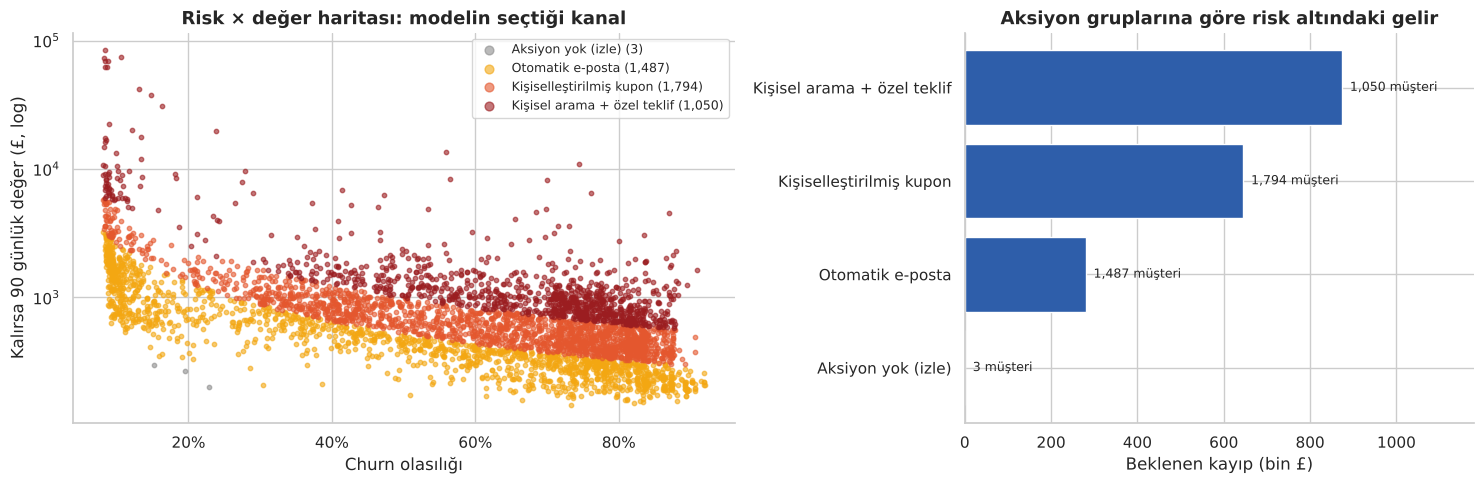

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
kanal_renk = {"⚪ Aksiyon yok (izle)": PALETTE["gri"], "🟡 Otomatik e-posta": PALETTE["sari"],
              "🟠 Kişiselleştirilmiş kupon": PALETTE["vurgu"], "🔴 Kişisel arama + özel teklif": "#9B1D20"}
for kanal, renk in kanal_renk.items():
    m_ = liste["aksiyon"] == kanal
    ax.scatter(liste.loc[m_, "churn_olasiligi"], liste.loc[m_, "kalirsa_90g_deger"], s=10, alpha=.6, color=renk, label=f"{kanal[2:]} ({m_.sum():,})")
ax.set_yscale("log"); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title="Risk × değer haritası: modelin seçtiği kanal", xlabel="Churn olasılığı", ylabel="Kalırsa 90 günlük değer (£, log)")
ax.legend(fontsize=9, markerscale=2)

ak = liste.assign(aksiyon=liste["aksiyon"].str[2:]).groupby("aksiyon").agg(Musteri=("churn_olasiligi", "size"), Risk=("beklenen_kayip", "sum")).sort_values("Risk")
axes[1].barh(ak.index, ak["Risk"] / 1e3, color=PALETTE["ana"])
for i, (r, m) in enumerate(zip(ak["Risk"], ak["Musteri"])):
    axes[1].text(r / 1e3, i, f"  {m:,} müşteri", va="center", fontsize=9)
axes[1].set(title="Aksiyon gruplarına göre risk altındaki gelir", xlabel="Beklenen kayıp (bin £)")
axes[1].set_xlim(0, ak["Risk"].max() / 1e3 * 1.35)
plt.tight_layout(); plt.show()

## 11. A/B Test Tasarımı: Kampanya Gerçekten İşe Yarıyor mu?

Projenin en büyük belirsizliği **ikna oranı**. 9. bölüm, kampanyanın mutlak kârlılığının tamamen bu sayıya bağlı olduğunu gösterdi: kupon için başa baş noktası yaklaşık %20. Bu sayı tahminle değil, **deneyle** öğrenilmeli.

**Tasarım:**
- **Kime:** Modelin kupon kanalına atadığı müşteriler (zaten hedeflenecek olanlar).
- **Nasıl:** Bu grubu rastgele ikiye böl: **müdahale** grubu kuponu alır, **kontrol** grubu almaz. Rastgele atama, iki grup arasındaki farkın kampanyadan kaynaklandığını garanti eder.
- **Ana metrik:** 90 günlük churn oranı. **İkincil metrik:** müşteri başına 90 günlük gelir.
- **İkna oranının ölçülmesi:** s = 1 − (müdahale churn oranı ÷ kontrol churn oranı).

**Kaç müşteri gerekir?** İki oranın karşılaştırması için standart güç analizi (%5 anlamlılık, %80 güç):

$$
n_{\text{grup başına}} = \frac{\big(z_{1-\alpha/2} + z_{1-\beta}\big)^2 \,\big[p_k(1-p_k) + p_m(1-p_m)\big]}{(p_k - p_m)^2}, \qquad p_m = p_k\,(1 - s)
$$

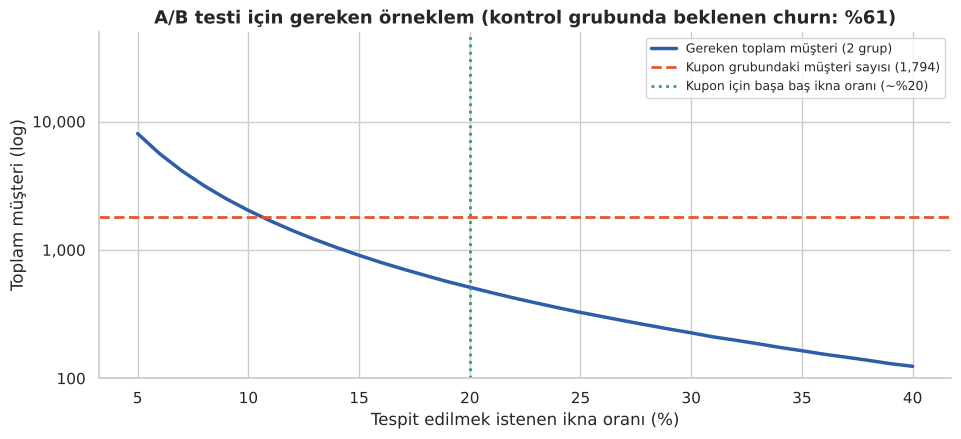

Kupon grubunda beklenen churn (kontrol): %61.2  |  Havuz: 1,794 müşteri


,Grup başına müşteri,Toplam müşteri,Mevcut havuz yeterli mi?
İkna oranı,,,
%10,1016,2032,❌ Hayır
%15,454,908,✅ Evet
%20,256,512,✅ Evet
%25,163,326,✅ Evet


In [27]:
from scipy.stats import norm

def grup_basina_n(p_kontrol, s, alfa=0.05, guc=0.80):
    p_mud = p_kontrol * (1 - s)
    z = norm.ppf(1 - alfa / 2) + norm.ppf(guc)
    return int(np.ceil(z**2 * (p_kontrol * (1 - p_kontrol) + p_mud * (1 - p_mud)) / (p_kontrol - p_mud) ** 2))

kupon_grubu = liste[liste["aksiyon"].str.contains("kupon")]
p_k = kupon_grubu["churn_olasiligi"].mean()
havuz = len(kupon_grubu)

s_aralik = np.arange(0.05, 0.41, 0.01)
n_egri = [grup_basina_n(p_k, s_) for s_ in s_aralik]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(s_aralik * 100, np.array(n_egri) * 2, lw=2.5, color=PALETTE["ana"], label="Gereken toplam müşteri (2 grup)")
ax.axhline(havuz, color=PALETTE["vurgu"], ls="--", lw=2, label=f"Kupon grubundaki müşteri sayısı ({havuz:,})")
ax.axvline(20, color=PALETTE["yesil"], ls=":", lw=2, label="Kupon için başa baş ikna oranı (~%20)")
ax.set_yscale("log"); ax.set_ylim(100, 50000)
ax.set(title=f"A/B testi için gereken örneklem (kontrol grubunda beklenen churn: %{p_k*100:.0f})",
       xlabel="Tespit edilmek istenen ikna oranı (%)", ylabel="Toplam müşteri (log)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}")); ax.legend(fontsize=9); plt.show()

tablo_ab = pd.DataFrame({"İkna oranı": [f"%{int(s_*100)}" for s_ in (0.10, 0.15, 0.20, 0.25)],
                         "Grup başına müşteri": [grup_basina_n(p_k, s_) for s_ in (0.10, 0.15, 0.20, 0.25)]})
tablo_ab["Toplam müşteri"] = tablo_ab["Grup başına müşteri"] * 2
tablo_ab["Mevcut havuz yeterli mi?"] = np.where(tablo_ab["Toplam müşteri"] <= havuz, "✅ Evet", "❌ Hayır")
print(f"Kupon grubunda beklenen churn (kontrol): %{p_k*100:.1f}  |  Havuz: {havuz:,} müşteri")
tablo_ab.set_index("İkna oranı")

**Gözlem:**
- Kupon grubundaki ~1.800 müşteri, **%15 veya üzeri** bir ikna oranını güvenilir şekilde ölçmeye yetiyor. Başa baş noktası (~%20) çevresindeki etkiler için ise test rahatça yapılabilir.
- **%10 gibi küçük bir etkiyi** ölçmek için havuz yetmiyor. Bu durumda ya test birden fazla ay sürdürülmeli ya da e-posta grubu gibi daha büyük bir havuzla başlanmalı.
- **Karar kuralı:** Ölçülen ikna oranı başa baş noktasının üzerindeyse kupon kampanyası tüm gruba yayılır; altındaysa bütçe ucuz kanallara kaydırılır. Ölçülen oran, 9. ve 10. bölümdeki varsayımın yerine doğrudan konur ve aksiyon listesi yeniden hesaplanır.
- **Gelir etkisi** churn'e göre çok daha gürültülü olduğu için ikincil metrik olarak izlenmeli; onu da anlamlı ölçmek çok daha büyük bir örneklem ister.

## 12. Sonuç ve İş Önerileri

### Ne yaptık?
Ham işlem verisinden başlayıp, **sızıntısız bir zaman tasarımıyla** iki tahmin modeli kurduk ve bunları **para cinsinden bir karar kuralına** bağladık. Klasik RFM analizini temel alıp üzerine geleceğe dönük tahmin, açıklanabilirlik ve optimizasyon katmanları ekledik.

### Temel bulgular
1. **Gecikme oranı**, sabit bir "X gün sessiz" kuralından daha akıllı bir alarm: her müşterinin kendi ritmine göre çalışıyor.
2. **Tek siparişli müşteriler** en büyük kayıp havuzu: ikinci siparişi tetikleyen bir hoş geldin akışı en yüksek getirili yatırımlardan biri olabilir.
3. **Risk × değer ile hedefleme**, eşit bütçeyle sadece riske göre hedeflemekten daha fazla kâr getiriyor: modelden bağımsız bir değer ölçüsüyle bile +£1.406 (%95 GA: £841 – £1.976). Kampanyanın **mutlak** kârlılığı ise ikna oranına bağlı ve A/B testiyle doğrulanmalı.
4. Karar kuralı (**beklenen kâr > 0**) maliyet ve ikna oranı değiştikçe kendini otomatik ayarlıyor.
5. **Daha sade model daha iyi:** İlk LightGBM ezberliyordu. Sadece eğitim setinde yapılan seçimle ayarlanan sade model, çapraz doğrulamada AUC'yi +0.027 artırdı (25 bölmenin 25'inde) ve kilitli test setinde PR-AUC ile kalibrasyonu iyileştirdi.
6. **Model zamanda genelleşiyor ama kalibrasyonu mevsime göre kayıyor:** Geriye dönük testlerde AUC korunuyor (0.745–0.768), fakat yazdan eğitilen model yılbaşı sezonunda churn'ü ~9 puan fazla tahmin ediyor.
7. **Değer tahmininde kayıp fonksiyonu kritik:** Tweedie kaybı R²'yi 0.36'dan 0.52'ye çıkardı; bu, klasik BG-NBD × Gamma-Gamma CLTV ile başa baş. BG-NBD 9 aylık veride müşteri kaybını modelleyemiyor (kayıp parametreleri sıfıra iniyor); churn'ü ayrı modelleyen hurdle yapı bu yüzden kampanya kararı için daha kullanışlı.
8. **İki değer yaklaşımını birleştirmek en iyisi:** Hurdle Tweedie ile klasik CLTV'nin ortalaması R²'yi 0.55'e çıkardı; ikisinden de iyi.
9. **Mevsim kalibrasyonu sıralamayı bozmadan olasılıkları düzeltiyor:** Geriye dönük testte Brier skoru 0.208'den 0.200'e indi ve hedef oran 5 puan hatalı olsa bile fayda korundu.
10. **Kampanyanın gerçek etkisi ölçülebilir:** Kupon grubundaki ~1.800 müşteri, %15 ve üzeri ikna oranlarını bir A/B testiyle güvenilir şekilde ölçmeye yetiyor.

### Pazarlama ekibine öneriler
| Kanal (modelin seçtiği) | Kime düşüyor? | Zamanlama |
|---|---|---|
| 🔴 Kişisel arama + özel teklif | Kaybedilecek değeri çok yüksek müşteriler | Hemen |
| 🟠 Kişiselleştirilmiş kupon | Riskli ve orta-yüksek değerli müşteriler | Bu hafta |
| 🟡 Otomatik e-posta | Riskli ama düşük değerli müşteriler (maliyeti neredeyse sıfır) | Otomatik akış |
| ⚪ Aksiyon yok | Kampanyanın kâr getirmediği müşteriler (zaten kalacak ya da değeri düşük) | Sadece izle |

> 💡 Siparişler hafta içi mesai saatlerinde yoğunlaştığı için iletişimler **salı–perşembe sabahları** gönderilmeli.

### Sınırlılıklar ve sonraki adımlar
- **İkna oranı varsayımdır.** Gerçek değer, 11. bölümde tasarlanan **A/B testi** ile ölçülmeli. Daha ileri bir adım olarak, kampanyaya *gerçekten tepki verecek* müşterileri bulan **uplift modelleme** kurulabilir.
- **Mevsimsellik:** Tahmin penceresi yılbaşı sezonuna denk geliyor. Birden fazla kesim tarihiyle (rolling window) eğitmek modeli daha sağlam yapar.
- **Ürüne dayalı özellikler:** Ürün kategorileri, kişiselleştirilmiş kupon için öneri sistemiyle birleştirilebilir.
- **Üretime alma:** Haftalık otomatik skorlama, model izleme (drift) ve CRM entegrasyonu.

---
*Teşekkürler! Soru ve geri bildirimler için [LinkedIn](https://www.linkedin.com/in/memreu) · [Kaggle](https://www.kaggle.com/memreu)*